# ForgeryGuard AI — M2 & M3 | Kaggle

**M2:** scratch CNN. **M3:** ImageNet ResNet18, frozen backbone and full fine-tuning.

**Inputs (Add Input):**
- Project originals and M1 artifacts: `mkajrfi/forgeryguard-ai`
- Forged images and masks: `defactodataset/defactocopymove`

These identifiers come from the supplied M1 notebook. They are not verification of a new link or of usage rights. Private datasets require access permissions for the Kaggle account used to run the notebook.

**Execution environment:** GPU and Internet access are required in Kaggle settings. Both datasets must be attached, and cells should be executed in order. Generated files are stored under `/kaggle/working/ForgeryGuard_AI_M2_M3`. Kaggle versions can preserve outputs through **Save Version → Save & Run All**; interactive outputs require an output-enabled save. Files from discarded sessions may not persist.

يتضمن هذا الدفتر مراحل M2 وM3 على بيئة Kaggle، مع الاعتماد على مجموعتي البيانات وتفعيل GPU وInternet عند التنفيذ. يتم الاحتفاظ بتقسيم M1؛ وتُستبعد التكرارات المتطابقة داخل التقسيم من جدول التدريب فقط مع تسجيلها، دون حذف ملفات المصدر. يتوقف التنفيذ عند اكتشاف تسرب بين التقسيمات أو تعارض في التسميات يستلزم مراجعة M1.

**Important limits:** M1 license/privacy review is still pending. This notebook does not clear those reviews or claim M1 is complete. Keep notebook/results private while reviewing permissions. The visual sample is training-only and needs an actual human review. Original JPG vs forged TIFF is a potential compression shortcut; common RGB decoding does not remove historical compression. An equal JPEG re-encoding stress test is reported separately; it cannot prove absence of that bias. Resizing to 224 may hide small manipulations. Exact pixel hashes cannot detect all near-duplicate scenes.

**W&B:** offline logging by default (no key). Before submission, sync those runs or choose online mode and add a Kaggle secret named `WANDB_API_KEY`. Local offline logs alone are not evidence of a completed online comparison.

**Recorded results:** Outputs shown in this saved notebook are retained from the original execution. Reproduction requires access to the referenced Kaggle datasets and environment.
Fixed seeds improve reproducibility; they do not guarantee bitwise-identical results across hardware or package versions.


## Shared — Step 1: Configuration and environment

Set one configuration, seeds, output location, and GPU checks. CPU training requires an explicit setting.

نوحّد الإعدادات ونثبت العشوائية. إذا لم يظهر GPU يتوقف التدريب برسالة واضحة، دون بدء تدريب طويل على CPU.


In [10]:
from pathlib import Path
import os, sys, json, random, time, hashlib, io, gc, shutil, subprocess
from datetime import datetime, timezone
from importlib.metadata import version, PackageNotFoundError
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from tqdm.auto import tqdm
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
    confusion_matrix, classification_report, roc_auc_score)

CFG = {
    'seed': 251, 'image_size': 224, 'batch_size': 32, 'num_workers': 2,
    'm2_epochs': 8, 'frozen_epochs': 8, 'finetune_epochs': 8,
    'patience': 3, 'lr_scratch': 1e-3, 'lr_frozen': 1e-3,
    'lr_finetune': 1e-4, 'weight_decay': 1e-4, 'threshold': 0.5,
    'ece_bins': 15, 'bootstrap_repeats': 2000,
    'jpeg_stress_quality': 90, 'allow_cpu_training': False,
    'wandb_mode': 'offline', 'wandb_project': 'ForgeryGuard-AI',
    'wandb_entity': None,
    # Optional explicit paths, only needed when multiple inputs match.
    'manifest_path': '', 'forged_dir': '', 'original_dir': '',
    'pretrained_weights_path': '',
    # Optional saved notebook output folder containing model subfolders.
    'resume_from_dir': '',
}
INPUT_ROOT = Path('/kaggle/input')
OUTPUT_DIR = Path('/kaggle/working/ForgeryGuard_AI_M2_M3')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def write_json(path, value):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')
    tmp.replace(path)

def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''): digest.update(block)
    return digest.hexdigest()

seed_all(CFG['seed'])
print('Python:', sys.version.split()[0], '| PyTorch:', torch.__version__)
print('Device:', DEVICE)
if DEVICE.type == 'cuda': print('GPU:', torch.cuda.get_device_name(0))
else: print('Enable GPU before the training cells. Audits can run on CPU.')
print('Output:', OUTPUT_DIR)
write_json(OUTPUT_DIR / 'config.json', CFG)


Python: 3.13.15 | PyTorch: 2.11.0+cu128
Device: cuda
GPU: Tesla T4
Output: /kaggle/working/ForgeryGuard_AI_M2_M3


## Shared — Step 2: Resolve attached data

Find the actual mounted paths. Missing and ambiguous inputs get different messages; explicit paths can resolve ambiguity.

نبحث داخل /kaggle/input بدل افتراض مسار ثابت. الرسالة توضح هل البيانات ناقصة أم توجد نسخ متعددة.


In [11]:

from pathlib import Path
import json

# تحديد مسارات البيانات مباشرة
INPUT_ROOT = Path("/kaggle/input")

PROJECT_INPUT = INPUT_ROOT / "datasets/mkajrfi/forgeryguard-ai"
DEFACTO_ROOT = INPUT_ROOT / "datasets/defactodataset/defactocopymove"

MANIFEST_PATH = PROJECT_INPUT / "dataset_split_portable.csv"
ORIGINAL_DIR = PROJECT_INPUT / "forgeryguard_originals/Original"
FORGED_DIR = DEFACTO_ROOT / "copymove_img/img"
MASK_DIR = DEFACTO_ROOT / "copymove_annotations/probe_mask"

# التحقق من المسارات
paths = {
    "Manifest": MANIFEST_PATH,
    "Originals": ORIGINAL_DIR,
    "Forged": FORGED_DIR,
    "Masks": MASK_DIR
}

for name, path in paths.items():
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")
    print(f"  {path}")

# قراءة بطاقة البيانات إن كانت موجودة
card_path = PROJECT_INPUT / "dataset_card.json"

DATASET_CARD = (
    json.loads(card_path.read_text())
    if card_path.is_file()
    else {}
)

# حفظ نسخة من بطاقة البيانات
write_json(
    OUTPUT_DIR / "source_dataset_card.json",
    DATASET_CARD
)

print("\nSTATUS: PATH CHECK COMPLETE")


Manifest: FOUND
  /kaggle/input/datasets/mkajrfi/forgeryguard-ai/dataset_split_portable.csv
Originals: FOUND
  /kaggle/input/datasets/mkajrfi/forgeryguard-ai/forgeryguard_originals/Original
Forged: FOUND
  /kaggle/input/datasets/defactodataset/defactocopymove/copymove_img/img
Masks: FOUND
  /kaggle/input/datasets/defactodataset/defactocopymove/copymove_annotations/probe_mask

STATUS: PATH CHECK COMPLETE


## Shared — Step 3: Preserve and verify M1 splits

Validate the exact source manifest and build original/forged rows. Class 0 = Original; class 1 = Forged.

نستخدم تقسيم m1 >
ونتحقق من أعداده. لا نعيد التقسيم عشوائيًا.


In [12]:
MANIFEST = pd.read_csv(MANIFEST_PATH, dtype=str)
required = ['source_group', 'split', 'original_filename', 'forged_filename']
assert set(required).issubset(MANIFEST.columns), 'Missing manifest columns'
assert MANIFEST[required].notna().all().all(), 'Missing manifest values'
expected = {'train': 12735, 'val': 2729, 'test': 2730}
assert MANIFEST['split'].value_counts().to_dict() == expected, 'Dataset version differs from supplied M1; inspect before changing expected counts.'
assert len(MANIFEST) == 18194
assert MANIFEST['source_group'].is_unique, 'Expected one pair per source in this M1 version'
for column in ['original_filename', 'forged_filename']:
    assert MANIFEST[column].is_unique, f'Duplicate filenames: {column}'
    assert MANIFEST[column].map(lambda s: Path(s).name == s).all(), 'Expected basenames only'
assert (MANIFEST['original_filename'].map(lambda s: Path(s).stem) == MANIFEST['source_group']).all()
assert (MANIFEST['forged_filename'].map(lambda s: Path(s).stem.rsplit('_', 1)[-1]) == MANIFEST['source_group']).all()

parts = []
for label, column, root in [(0, 'original_filename', ORIGINAL_DIR), (1, 'forged_filename', FORGED_DIR)]:
    part = MANIFEST[['source_group', 'split', column]].rename(columns={column: 'filename'}).copy()
    part['label'] = label
    part['path'] = part['filename'].map(lambda s: str(root / s))
    parts.append(part)
DATA_RAW = pd.concat(parts, ignore_index=True)
missing = DATA_RAW.loc[~DATA_RAW['path'].map(lambda p: Path(p).is_file())]
missing.to_csv(OUTPUT_DIR / 'missing_images.csv', index=False)
assert missing.empty, f'{len(missing)} images missing; check attached dataset versions.'
assert DATA_RAW.groupby('source_group')['split'].nunique().max() == 1
MANIFEST[required].to_csv(OUTPUT_DIR / 'm1_split_preserved.csv', index=False)
print('Pairs:', len(MANIFEST), '| Images:', len(DATA_RAW))
display(pd.crosstab(DATA_RAW['split'], DATA_RAW['label']))


Pairs: 18194 | Images: 36388


label,0,1
split,,
test,2730,2730
train,12735,12735
val,2729,2729


## Shared — Step 4: Automatic Conflicting-Pair Cleaning

Audit image integrity and decoded RGB content. Automatically identify identical images with conflicting labels and exclude their entire source pairs, without hard-coded source IDs. Record every exclusion and preserve remaining split assignments. Stop if exact content appears across different splits.

نفحص سلامة الصور ومحتوى RGB، ونستبعد تلقائيًا أزواج المصدر المرتبطة بصور متطابقة ذات تسميات متعارضة، دون تحديد أرقام صور مسبقًا. نوثق الاستبعادات ونحافظ على تقسيم بقية الصور. نتوقف إذا ظهر تطابق محتوى بين التقسيمات.

In [13]:
from pathlib import Path
from importlib.metadata import version
import hashlib
import json
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

# ==================================================
# 1. التحقق من متغيرات الخطوات السابقة
# ==================================================
needed = ["MANIFEST", "DATA_RAW", "OUTPUT_DIR", "write_json"]
missing = [name for name in needed if name not in globals()]

if missing:
    raise RuntimeError(f"Run Steps 1–3 first. Missing: {missing}")

assert not DATA_RAW.empty
assert DATA_RAW["source_group"].map(
    lambda value: isinstance(value, str)
).all(), "source_group must remain a string."

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

manifest_columns = [
    "source_group", "split",
    "original_filename", "forged_filename"
]

identity_columns = [
    "source_group", "split", "filename", "label", "path"
]

# ==================================================
# 2. بصمة البيانات للتحقق من التقرير المحفوظ
# ==================================================
audit_fingerprint = hashlib.sha256()

audit_fingerprint.update(
    MANIFEST[manifest_columns].to_csv(index=False).encode()
)
audit_fingerprint.update(str(version("Pillow")).encode())

for row in tqdm(
    DATA_RAW.itertuples(index=False),
    total=len(DATA_RAW),
    desc="Checking file metadata",
    unit="image"
):
    stat = Path(row.path).stat()
    audit_fingerprint.update(
        f"{row.path}|{stat.st_size}|{stat.st_mtime_ns}".encode()
    )

AUDIT_ID = audit_fingerprint.hexdigest()

audit_path = OUTPUT_DIR / "image_integrity_audit.csv"
audit_meta = OUTPUT_DIR / "image_integrity_audit_meta.json"

cache_ok = False

if audit_path.is_file() and audit_meta.is_file():
    try:
        metadata = json.loads(
            audit_meta.read_text(encoding="utf-8")
        )

        if metadata.get("audit_id") == AUDIT_ID:
            cached = pd.read_csv(
                audit_path,
                dtype={"source_group": str}
            )

            required_audit_columns = set(identity_columns) | {
                "pixel_hash", "height", "width", "error"
            }

            if (
                required_audit_columns.issubset(cached.columns)
                and len(cached) == len(DATA_RAW)
            ):
                cached_identity = (
                    cached[identity_columns]
                    .reset_index(drop=True)
                    .astype(str)
                )
                current_identity = (
                    DATA_RAW[identity_columns]
                    .reset_index(drop=True)
                    .astype(str)
                )

                cache_ok = cached_identity.equals(current_identity)

                if cache_ok:
                    AUDIT = cached

    except (ValueError, OSError):
        cache_ok = False

# ==================================================
# 3. فحص جميع الصور عند عدم وجود تقرير مطابق
# ==================================================
if cache_ok:
    print("Reusing matching full RGB audit.")

else:
    records = []

    for row in tqdm(
        DATA_RAW.itertuples(index=False),
        total=len(DATA_RAW),
        desc="Full RGB audit",
        unit="image"
    ):
        result = {
            "source_group": row.source_group,
            "split": row.split,
            "filename": row.filename,
            "label": int(row.label),
            "path": row.path
        }

        try:
            with Image.open(row.path) as image:
                rgb = np.asarray(image.convert("RGB"))

            digest = hashlib.sha256(
                str(rgb.shape).encode() + rgb.tobytes()
            ).hexdigest()

            result.update(
                pixel_hash=digest,
                height=int(rgb.shape[0]),
                width=int(rgb.shape[1]),
                error=""
            )

        except Exception as exc:
            result.update(
                pixel_hash="",
                height=0,
                width=0,
                error=f"{type(exc).__name__}: {exc}"
            )

        records.append(result)

    AUDIT = pd.DataFrame(records)
    AUDIT.to_csv(audit_path, index=False)
    write_json(audit_meta, {"audit_id": AUDIT_ID})

# ==================================================
# 4. فحص التلف والتسرب قبل أي استبعاد
# ==================================================
corrupt = AUDIT.loc[
    AUDIT["error"].fillna("").ne("")
].copy()

corrupt.to_csv(
    OUTPUT_DIR / "corrupt_images.csv",
    index=False
)

assert corrupt.empty, (
    f"{len(corrupt)} corrupt images found. "
    "Inspect corrupt_images.csv before proceeding."
)

assert AUDIT["pixel_hash"].notna().all()
assert AUDIT["pixel_hash"].ne("").all()

raw_split_counts = (
    AUDIT.groupby("pixel_hash")["split"].nunique()
)

raw_leak_hashes = set(
    raw_split_counts[raw_split_counts > 1].index
)

raw_label_counts = (
    AUDIT.groupby("pixel_hash")["label"].nunique()
)

raw_conflict_hashes = set(
    raw_label_counts[raw_label_counts > 1].index
)

AUDIT.loc[
    AUDIT["pixel_hash"].isin(
        raw_conflict_hashes | raw_leak_hashes
    )
].to_csv(
    OUTPUT_DIR / "content_conflicts_or_leakage.csv",
    index=False
)

assert not raw_leak_hashes, (
    "Exact-content leakage across splits detected. "
    "Correct M1; no automatic re-splitting was performed."
)

# ==================================================
# 5. اكتشاف مصادر التعارض تلقائيًا
# لا توجد أرقام صور محددة مسبقًا
# ==================================================
conflicting_images = AUDIT.loc[
    AUDIT["pixel_hash"].isin(raw_conflict_hashes)
].copy()

EXCLUDED_SOURCE_GROUPS = set(
    conflicting_images["source_group"]
)

# استبعاد جميع صور المصدر المتأثر، وليس أحد طرفي التعارض فقط
excluded_rows = AUDIT.loc[
    AUDIT["source_group"].isin(EXCLUDED_SOURCE_GROUPS)
].copy()

excluded_rows["directly_conflicting"] = (
    excluded_rows["pixel_hash"].isin(raw_conflict_hashes)
)

excluded_rows["exclusion_reason"] = (
    "Source pair linked to identical decoded RGB content "
    "with conflicting classification labels."
)

conflicting_images.drop(columns=["path"]).to_csv(
    OUTPUT_DIR / "conflicting_label_images.csv",
    index=False
)

excluded_rows.drop(columns=["path"]).to_csv(
    OUTPUT_DIR / "conflicting_pair_exclusions.csv",
    index=False
)

pd.DataFrame({
    "source_group": sorted(EXCLUDED_SOURCE_GROUPS),
    "reason": [
        "Source linked to pixel-identical images with conflicting labels"
    ] * len(EXCLUDED_SOURCE_GROUPS)
}).to_csv(
    OUTPUT_DIR / "source_group_exclusions.csv",
    index=False
)

# ==================================================
# 6. التحقق من البيانات بعد استبعاد مصادر التعارض
# ==================================================
CLEAN_AUDIT = AUDIT.loc[
    ~AUDIT["source_group"].isin(EXCLUDED_SOURCE_GROUPS)
].copy()

assert not CLEAN_AUDIT.empty, (
    "No data remains after conflict cleaning. Inspect the audit."
)

remaining_label_counts = (
    CLEAN_AUDIT.groupby("pixel_hash")["label"].nunique()
)
conflict_hashes = set(
    remaining_label_counts[remaining_label_counts > 1].index
)

remaining_split_counts = (
    CLEAN_AUDIT.groupby("pixel_hash")["split"].nunique()
)
leak_hashes = set(
    remaining_split_counts[remaining_split_counts > 1].index
)

assert not conflict_hashes, "Conflicting labels remain."
assert not leak_hashes, "Exact-content leakage remains."

dimensions = (
    CLEAN_AUDIT.groupby("source_group")[["height", "width"]]
    .nunique()
)

assert (dimensions == 1).all().all(), (
    "Original/forged dimensions differ. Inspect pair matching."
)

# ==================================================
# 7. إزالة سجلات التكرار بنفس التسمية داخل التقسيم
# ==================================================
duplicate_rows = CLEAN_AUDIT.duplicated(
    subset="pixel_hash",
    keep="first"
)

CLEAN_AUDIT.loc[duplicate_rows].drop(
    columns=["path"]
).to_csv(
    OUTPUT_DIR / "within_split_duplicate_exclusions.csv",
    index=False
)

DATA = (
    CLEAN_AUDIT.loc[~duplicate_rows]
    .reset_index(drop=True)
    .copy()
)

assert not DATA.empty
assert DATA["pixel_hash"].is_unique
assert not DATA["source_group"].isin(EXCLUDED_SOURCE_GROUPS).any()
assert DATA.groupby("source_group")["split"].nunique().max() == 1
assert set(DATA["split"]) == {"train", "val", "test"}

# التحقق من الحفاظ على تقسيم M1 لكل مصدر متبقٍ
assignments = MANIFEST[
    ["source_group", "split"]
].drop_duplicates()

assert assignments["source_group"].is_unique

saved_assignment = assignments.set_index("source_group")["split"]

assert (
    DATA["source_group"].map(saved_assignment) == DATA["split"]
).all(), "A retained source has a changed split assignment."

# ==================================================
# 8. حفظ النتائج
# ==================================================
split_counts = pd.crosstab(
    DATA["split"], DATA["label"]
).reindex(
    index=["train", "val", "test"],
    columns=[0, 1],
    fill_value=0
)

assert split_counts.gt(0).all().all(), (
    "A split is missing one of the classes."
)

split_counts.columns = ["Original", "Forged"]

DATA.drop(columns=["path"]).to_csv(
    OUTPUT_DIR / "classification_manifest_portable.csv",
    index=False
)

split_counts.to_csv(
    OUTPUT_DIR / "effective_split_counts.csv"
)

DATA_ID = hashlib.sha256(
    DATA[
        ["source_group", "split", "label", "pixel_hash"]
    ].to_csv(index=False).encode()
).hexdigest()

write_json(
    OUTPUT_DIR / "cleaning_decisions.json",
    {
        "cleaning_rule": (
            "Automatically exclude all sources linked to "
            "pixel-identical images with conflicting labels."
        ),
        "input_images": int(len(AUDIT)),
        "original_conflicting_hashes": len(raw_conflict_hashes),
        "directly_conflicting_images": int(len(conflicting_images)),
        "excluded_source_groups": sorted(EXCLUDED_SOURCE_GROUPS),
        "excluded_source_images": int(len(excluded_rows)),
        "additional_duplicate_exclusions": int(duplicate_rows.sum()),
        "retained_images": int(len(DATA)),
        "remaining_conflicting_hashes": len(conflict_hashes),
        "cross_split_pixel_hashes": len(leak_hashes),
        "split_assignments_preserved": True,
        "source_files_deleted": False,
        "data_id": DATA_ID
    }
)

print("\n========== STEP 4 SUMMARY ==========")
print("Input images:", len(AUDIT))
print("Conflicting RGB hashes:", len(raw_conflict_hashes))
print("Directly conflicting images:", len(conflicting_images))
print("Automatically excluded source groups:", len(EXCLUDED_SOURCE_GROUPS))
print("Excluded source images:", len(excluded_rows))
print("Additional duplicate exclusions:", int(duplicate_rows.sum()))
print("Retained classification images:", len(DATA))
print("Remaining conflicting hashes:", len(conflict_hashes))
print("Cross-split pixel hashes:", len(leak_hashes))

display(split_counts)

print("\nStep 4 completed successfully.")
print("Source files unchanged. Remaining split assignments preserved.")

Checking file metadata:   0%|          | 0/36388 [00:00<?, ?image/s]

Full RGB audit:   0%|          | 0/36388 [00:00<?, ?image/s]


========== STEP 4 SUMMARY ==========
Input images: 36388
Conflicting RGB hashes: 4
Directly conflicting images: 8
Automatically excluded source groups: 4
Excluded source images: 8
Additional duplicate exclusions: 0
Retained classification images: 36380
Remaining conflicting hashes: 0
Cross-split pixel hashes: 0


,Original,Forged
split,,
train,12733,12733
val,2728,2728
test,2729,2729



Step 4 completed successfully.
Source files unchanged. Remaining split assignments preserved.


## Shared — Step 5: Visual annotation sample and review record

Display 12 fixed training pairs with masks and saved boxes. Complete the review record after inspection. This sample does not certify privacy, label accuracy, or annotation quality for the full dataset.

نعرض عينة ثابتة من التدريب: الأصلية والمعدلة والقناع والمربع. تُوثّق ملاحظات المراجعة البشرية في الخلية التالية بعد فحص العينات. لا نعتبر المراجعة مكتملة تلقائيًا.


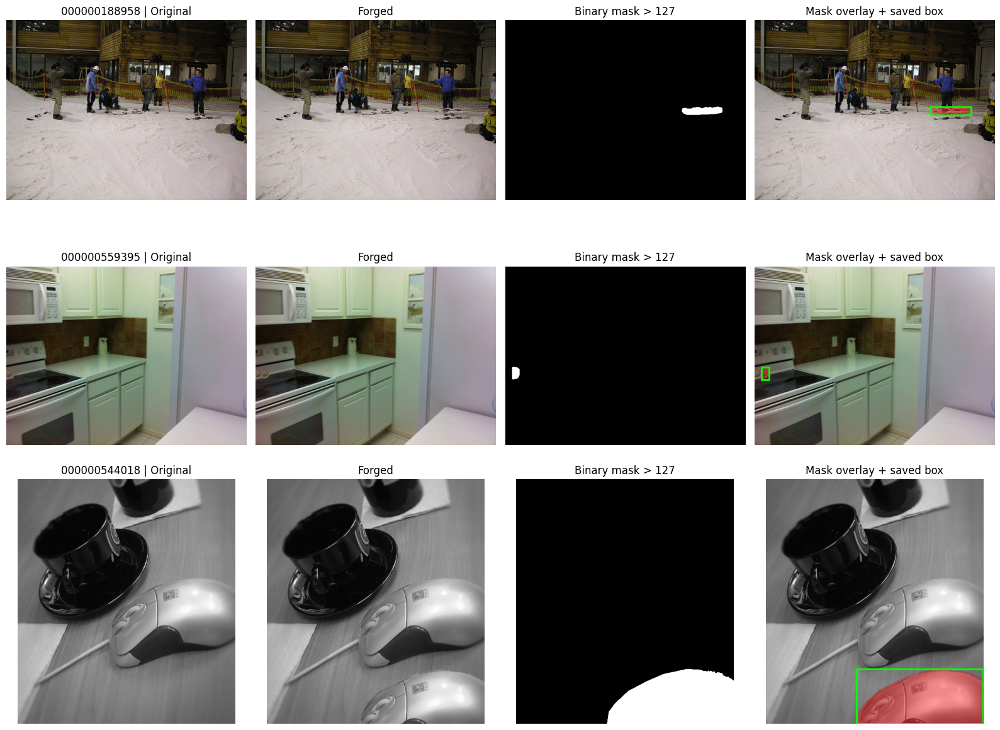

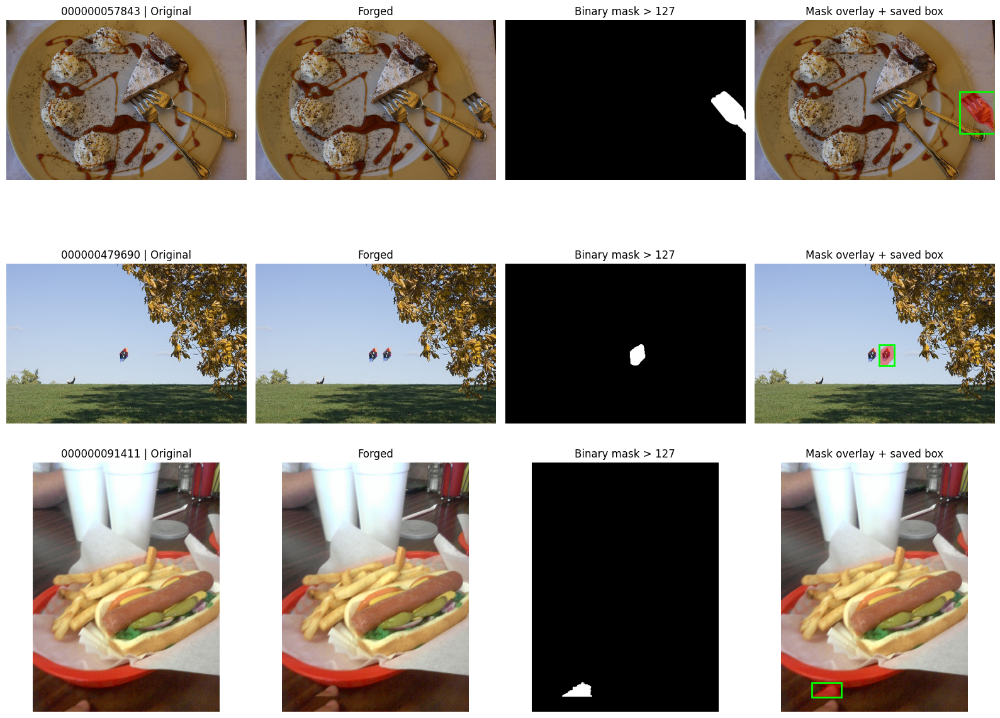

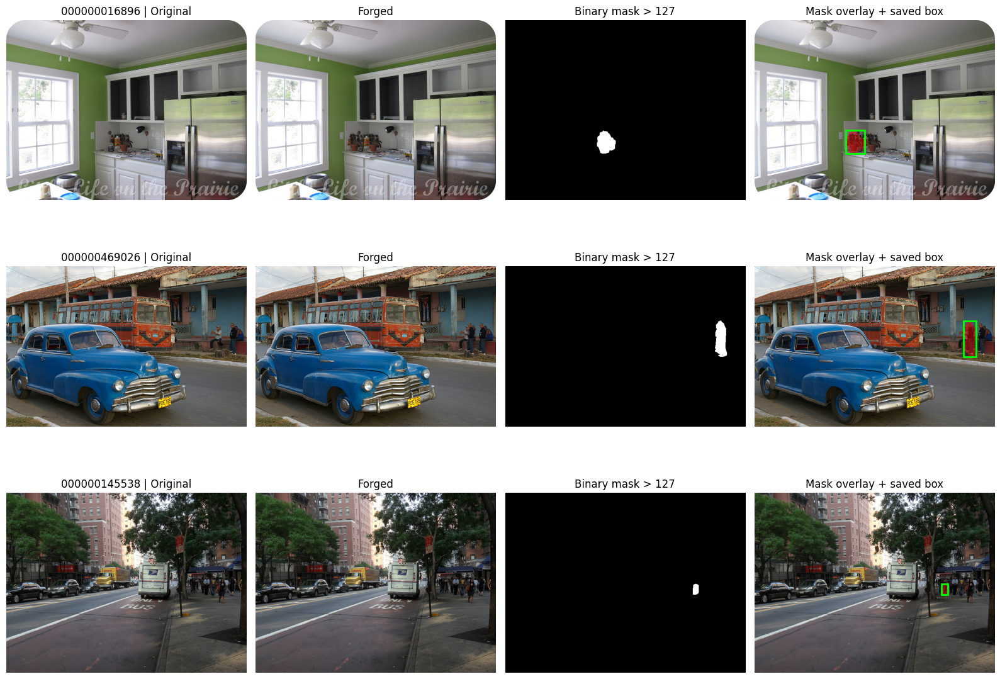

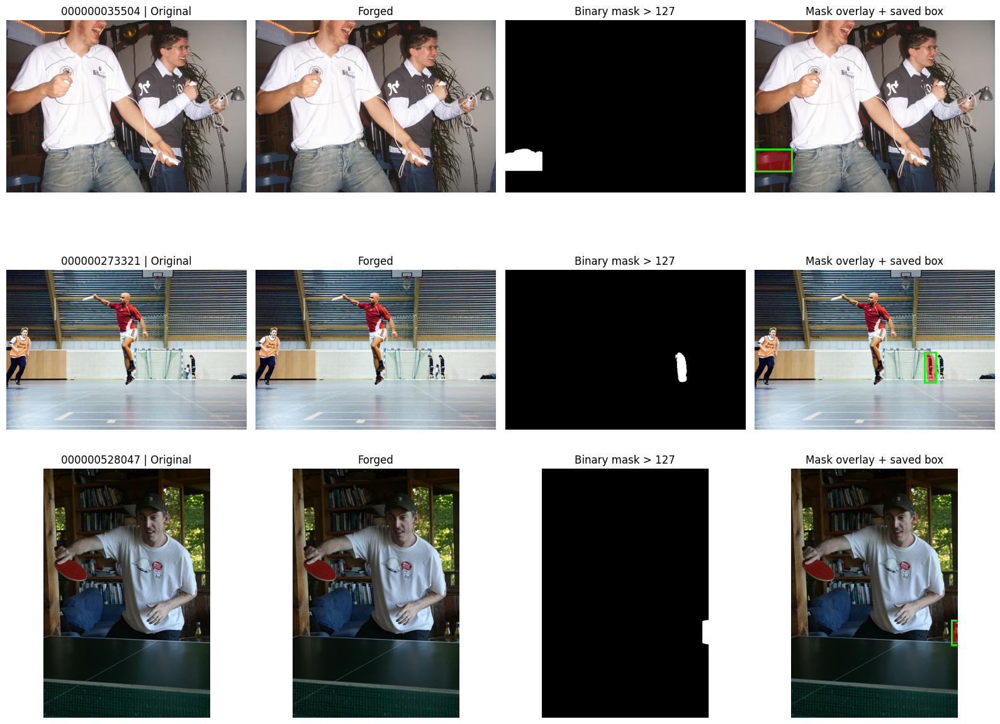

Displayed training pairs: 12
Source groups: ['000000188958', '000000559395', '000000544018', '000000057843', '000000479690', '000000091411', '000000016896', '000000469026', '000000145538', '000000035504', '000000273321', '000000528047']
Structural issues: 0

Human visual review: PENDING
No images removed. No split assignments changed.


In [14]:
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# التأكد من تشغيل الخطوات السابقة
needed = [
    "MANIFEST", "DATA", "PROJECT_INPUT",
    "ORIGINAL_DIR", "FORGED_DIR", "MASK_DIR", "OUTPUT_DIR"
]
missing = [name for name in needed if name not in globals()]

if missing:
    raise RuntimeError(f"Run previous steps first. Missing: {missing}")

if MASK_DIR is None:
    raise FileNotFoundError("Probe mask directory was not found.")

# اختيار مصادر تحتوي صورتين مقبولتين: أصلية ومعدلة
accepted_labels = pd.crosstab(
    DATA["source_group"], DATA["label"]
).reindex(columns=[0, 1], fill_value=0)

accepted_groups = accepted_labels.index[
    (accepted_labels[0] == 1) & (accepted_labels[1] == 1)
]

eligible_pairs = MANIFEST.loc[
    (MANIFEST["split"] == "train")
    & MANIFEST["source_group"].isin(accepted_groups)
].copy()

if "EXCLUDED_SOURCE_GROUPS" in globals():
    assert not eligible_pairs["source_group"].isin(
        EXCLUDED_SOURCE_GROUPS
    ).any()

assert len(eligible_pairs) >= 12, "Fewer than 12 eligible training pairs."

visual_sample = eligible_pairs.sample(
    n=12,
    random_state=251
).reset_index(drop=True)

# قراءة المربعات المحفوظة
bbox_paths = sorted(
    PROJECT_INPUT.rglob("tampering_bounding_boxes.csv")
)

if len(bbox_paths) != 1:
    raise FileNotFoundError(
        f"Expected one bounding-box CSV; found {len(bbox_paths)}."
    )

BBOX = pd.read_csv(
    bbox_paths[0],
    dtype={"source_group": str}
)

box_columns = {
    "forged_filename", "xmin", "ymin", "xmax", "ymax"
}
assert box_columns.issubset(BBOX.columns), (
    f"Missing bounding-box columns: {box_columns - set(BBOX.columns)}"
)

box_lookup = BBOX.groupby("forged_filename", sort=False)

VISUAL_ISSUES = []
sample_checks = []

# عرض ثلاثة أزواج في كل لوحة
for start in range(0, len(visual_sample), 3):
    batch = visual_sample.iloc[start:start + 3]

    fig, axes = plt.subplots(
        len(batch), 4,
        figsize=(16, 4 * len(batch)),
        squeeze=False
    )

    for row_index, row in enumerate(batch.itertuples(index=False)):
        group = row.source_group
        original_path = ORIGINAL_DIR / row.original_filename
        forged_path = FORGED_DIR / row.forged_filename
        mask_path = MASK_DIR / (
            Path(row.forged_filename).stem + ".jpg"
        )

        issues = []
        original = forged = mask = None

        # فتح الصور والقناع وتسجيل أي مشكلة
        try:
            with Image.open(original_path) as im:
                original = np.asarray(im.convert("RGB"))

            with Image.open(forged_path) as im:
                forged = np.asarray(im.convert("RGB"))

            with Image.open(mask_path) as im:
                mask = np.asarray(im.convert("L")) > 127

        except Exception as exc:
            issues.append(
                f"Image/mask read error: {type(exc).__name__}: {exc}"
            )

        for ax in axes[row_index]:
            ax.axis("off")

        axes[row_index, 0].set_title(f"{group} | Original")
        axes[row_index, 1].set_title("Forged")
        axes[row_index, 2].set_title("Binary mask > 127")
        axes[row_index, 3].set_title("Mask overlay + saved box")

        if original is not None:
            axes[row_index, 0].imshow(original)

        if forged is not None:
            axes[row_index, 1].imshow(forged)
            axes[row_index, 3].imshow(forged)

        if mask is not None:
            axes[row_index, 2].imshow(
                mask, cmap="gray", vmin=0, vmax=1
            )

            if not mask.any():
                issues.append("Empty binary mask")

        if original is not None and forged is not None:
            if original.shape != forged.shape:
                issues.append("Original/forged dimensions differ")

        # عرض القناع فوق الصورة المعدلة
        if mask is not None and forged is not None:
            if mask.shape != forged.shape[:2]:
                issues.append("Mask/forged dimensions differ")
            else:
                overlay = np.zeros(
                    (*mask.shape, 4), dtype=np.float32
                )
                overlay[mask] = [1.0, 0.0, 0.0, 0.4]
                axes[row_index, 3].imshow(overlay)

        # عرض المربعات المحفوظة والتحقق من حدودها
        n_boxes = 0

        if row.forged_filename not in box_lookup.groups:
            issues.append("Saved bounding box missing")

        elif forged is not None:
            height, width = forged.shape[:2]

            for box in box_lookup.get_group(
                row.forged_filename
            ).itertuples(index=False):

                n_boxes += 1

                try:
                    xmin, ymin, xmax, ymax = [
                        float(getattr(box, name))
                        for name in ["xmin", "ymin", "xmax", "ymax"]
                    ]

                    coordinates = [xmin, ymin, xmax, ymax]

                    if not np.isfinite(coordinates).all():
                        issues.append("Non-finite box coordinates")
                        continue

                    if not (
                        0 <= xmin < xmax <= width
                        and 0 <= ymin < ymax <= height
                    ):
                        issues.append("Invalid box coordinates")
                        continue

                    axes[row_index, 3].add_patch(
                        Rectangle(
                            (xmin, ymin),
                            xmax - xmin,
                            ymax - ymin,
                            fill=False,
                            edgecolor="lime",
                            linewidth=2
                        )
                    )

                except (TypeError, ValueError) as exc:
                    issues.append(f"Invalid box values: {exc}")

        sample_checks.append({
            "source_group": group,
            "original_filename": row.original_filename,
            "forged_filename": row.forged_filename,
            "mask_filename": mask_path.name,
            "n_saved_boxes": n_boxes,
            "structural_issues": " | ".join(issues)
        })

        VISUAL_ISSUES.extend(
            f"{group}: {issue}" for issue in issues
        )

    plt.tight_layout()
    plt.show()
    plt.close(fig)

# حفظ العينة ونتائج الفحص البرمجي
visual_sample.to_csv(
    OUTPUT_DIR / "visual_audit_sample.csv",
    index=False
)

pd.DataFrame(sample_checks).to_csv(
    OUTPUT_DIR / "visual_audit_sample_checks.csv",
    index=False
)

# لا نعتمد المراجعة البشرية تلقائيًا
VISUAL_REVIEW_COMPLETED = False

print("Displayed training pairs:", len(visual_sample))
print("Source groups:", visual_sample["source_group"].tolist())
print("Structural issues:", len(VISUAL_ISSUES))

for issue in VISUAL_ISSUES:
    print("-", issue)

print("\nHuman visual review: PENDING")
print("No images removed. No split assignments changed.")

assert not VISUAL_ISSUES, (
    "Sample structural issues found. Inspect them before proceeding."
)

In [15]:
VISUAL_REVIEW_COMPLETED = True
VISUAL_REVIEW_NOTE = 'Reviewed 12 training pairs: masks and bounding boxes visually match the edited regions; small and edge-adjacent edits noted.'
OBSERVED_ISSUE_GROUPS = []
review_record = {
    'completed': VISUAL_REVIEW_COMPLETED, 'note': VISUAL_REVIEW_NOTE,
    'sample_source_groups': visual_sample['source_group'].tolist(),
    'observed_issue_groups': OBSERVED_ISSUE_GROUPS,
    'scope': '12 training pairs only; no statistical label-error bound claimed',
    'privacy_review': DATASET_CARD.get('privacy_review', 'PENDING'),
    'license_review': DATASET_CARD.get('license_review', 'PENDING'),
}
assert not VISUAL_REVIEW_COMPLETED or VISUAL_REVIEW_NOTE.strip(), 'Record actual findings.'
write_json(OUTPUT_DIR / 'visual_review.json', review_record)
if OBSERVED_ISSUE_GROUPS:
    raise RuntimeError('Resolve the recorded image/annotation issues in M1 before training.')
print('Human review status:', 'RECORDED' if VISUAL_REVIEW_COMPLETED else 'PENDING')
print('Training results remain provisional while M1 manual reviews are pending.')


Human review status: PENDING
Training results remain provisional while M1 manual reviews are pending.


### Visual review — 12 training pairs (post-run inspection)

The 12 displayed original/forged pairs, binary masks and saved bounding boxes were visually inspected using the retained notebook figures.

- **Labels:** The visible original–forged differences are consistent with the sampled copy-move edits.
- **Annotations:** Masks and boxes visually cover the edited regions; no clear mismatch was identified in this sample.
- **Observation:** Several edits are subtle or close to image borders (notably `000000528047`). These remain challenging cases; no annotation defect is confirmed.

**Scope:** Qualitative inspection of **12 training pairs only**; not a dataset-wide validation or privacy/licensing clearance. The `PENDING` text in saved cell outputs reflects the **earlier Kaggle execution**, retained unchanged for provenance. The review flag and note above were updated afterward; that cell has **not been re-executed**.

## Shared — Step 6: Datasets and deterministic loaders

Use identical RGB preprocessing for all models. Only training receives horizontal flips. No crop is used because a crop could remove the forged region. Validation/test are deterministic. JPEG stress preprocessing is fixed in advance.

نستخدم التحويلات نفسها للمقارنة العادلة. التحسين العشوائي للتدريب فقط، ونتجنب القص حتى لا تختفي منطقة التلاعب. إعادة ضغط JPEG اختبار إضافي منفصل وليست إزالة مؤكدة لتحيز الضغط.


In [16]:
train_tf = transforms.Compose([
    transforms.Resize((CFG['image_size'], CFG['image_size']), antialias=True),
    transforms.RandomHorizontalFlip(0.5), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
    transforms.Resize((CFG['image_size'], CFG['image_size']), antialias=True),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class ForgeryDataset(Dataset):
    def __init__(self, frame, transform, jpeg_quality=None):
        self.frame = frame.reset_index(drop=True)
        self.transform, self.jpeg_quality = transform, jpeg_quality
    def __len__(self): return len(self.frame)
    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row['path']) as im: image = im.convert('RGB')
        if self.jpeg_quality is not None:
            buffer = io.BytesIO()
            image.save(buffer, format='JPEG', quality=self.jpeg_quality, subsampling=0)
            buffer.seek(0)
            with Image.open(buffer) as compressed: image = compressed.convert('RGB')
        return self.transform(image), int(row['label'])

def worker_seed(worker_id):
    seed = torch.initial_seed() % (2**32)
    np.random.seed(seed); random.seed(seed)

train_df = DATA[DATA['split'] == 'train'].reset_index(drop=True)
val_df = DATA[DATA['split'] == 'val'].reset_index(drop=True)
test_df = DATA[DATA['split'] == 'test'].reset_index(drop=True)

def make_loader(frame, training=False, epoch=0, jpeg_quality=None):
    generator = torch.Generator().manual_seed(CFG['seed'] + epoch)
    return DataLoader(ForgeryDataset(frame, train_tf if training else eval_tf, jpeg_quality),
        batch_size=CFG['batch_size'], shuffle=training, num_workers=CFG['num_workers'],
        pin_memory=DEVICE.type == 'cuda', worker_init_fn=worker_seed,
        generator=generator, persistent_workers=False)

val_loader = make_loader(val_df)
test_loader = make_loader(test_df)
xb, yb = next(iter(make_loader(train_df, training=True)))
assert xb.shape[1:] == (3, CFG['image_size'], CFG['image_size'])
assert torch.isfinite(xb).all() and set(yb.tolist()).issubset({0, 1})
probe = ForgeryDataset(val_df, eval_tf)
assert torch.equal(probe[0][0], probe[0][0])
print('Batch:', tuple(xb.shape), '| Labels:', yb[:12].tolist())
print('Training class counts:', train_df['label'].value_counts().to_dict())
del xb, yb


Batch: (32, 3, 224, 224) | Labels: [0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1]
Training class counts: {0: 12733, 1: 12733}


## Shared — Step 7: W&B tracking and pretrained weights

Prepare offline/online logging and the official ImageNet weights before any long training. Never replace unavailable pretrained weights with random initialization. Credentials are read from Kaggle Secrets, never printed or saved.

نجهز W&B والأوزان قبل التدريب. الوضع الافتراضي Offline لحفظ التجارب محليًا، وتحتاج مزامنتها لاحقًا. للوضع Online غيّر الإعداد وأضف المفتاح في Kaggle Secrets باسم WANDB_API_KEY.


In [17]:
if DEVICE.type != 'cuda' and not CFG['allow_cpu_training']:
    raise RuntimeError('GPU unavailable. Kaggle Settings -> Accelerator -> GPU, restart, then rerun. CPU mode is only for intentional small checks.')
try:
    import wandb
except ImportError:
    print('Installing W&B; Kaggle Internet must be enabled.')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'wandb'], check=True)
    import wandb
assert CFG['wandb_mode'] in {'offline', 'online'}
if CFG['wandb_mode'] == 'online':
    api_key = os.environ.get('WANDB_API_KEY', '')
    if not api_key:
        try:
            from kaggle_secrets import UserSecretsClient
            api_key = UserSecretsClient().get_secret('WANDB_API_KEY')
        except Exception:
            raise RuntimeError('Add and enable Kaggle secret WANDB_API_KEY, or choose offline mode.') from None
    wandb.login(key=api_key, relogin=True)
    del api_key

weights_enum = models.ResNet18_Weights.IMAGENET1K_V1
if CFG['pretrained_weights_path']:
    PRETRAINED_PATH = Path(CFG['pretrained_weights_path'])
    if not PRETRAINED_PATH.is_file():
        raise FileNotFoundError('pretrained_weights_path does not point to an existing file.')
else:
    PRETRAINED_PATH = Path(torch.hub.get_dir()) / 'checkpoints' / Path(weights_enum.url).name
if not PRETRAINED_PATH.is_file():
    candidates = list(INPUT_ROOT.rglob('resnet18-f37072fd.pth'))
    if len(candidates) == 1: PRETRAINED_PATH = candidates[0]
    else:
        try:
            # Official download verifies the hash embedded in the filename.
            weights_enum.get_state_dict(progress=True, check_hash=True)
        except Exception:
            raise RuntimeError('Enable Internet or attach official resnet18-f37072fd.pth and set pretrained_weights_path.') from None
assert PRETRAINED_PATH.is_file(), 'Official pretrained weights were not found after download.'
PRETRAINED_SHA = file_sha256(PRETRAINED_PATH)
assert PRETRAINED_SHA.startswith('f37072fd'), 'Weights do not match the official ImageNet V1 hash prefix.'
probe_model = models.resnet18(weights=None)
probe_model.load_state_dict(torch.load(PRETRAINED_PATH, map_location='cpu', weights_only=True), strict=True)
del probe_model
print('W&B mode:', CFG['wandb_mode'], '| Pretrained weights verified:', PRETRAINED_PATH.name)
print('Offline runs must be synced before submitting a W&B comparison.')


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 224MB/s]


W&B mode: offline | Pretrained weights verified: resnet18-f37072fd.pth
Offline runs must be synced before submitting a W&B comparison.


## Shared — Step 8: Metrics and evaluation utilities

Report per-class precision/recall/F1, macro-F1, accuracy, ROC-AUC and ECE. A source-group bootstrap supplies a 95% accuracy interval for paired images. Top-2 accuracy is trivial in a two-class task and is labelled as such.

نحسب المقاييس لكل فئة، ومعايرة الثقة ECE. نحسب مجال الثقة بإعادة أخذ عينات من مجموعات المصدر حتى تبقى علاقة الأصلية والمعدلة محفوظة.


In [18]:
def calibration_data(labels, probs, n_bins=15):
    labels, probs = np.asarray(labels), np.asarray(probs)
    pred = (probs >= 0.5).astype(int)
    confidence = np.maximum(probs, 1 - probs)
    correct = (pred == labels).astype(float)
    # Include confidence == 1 in the last bin.
    bin_ids = np.minimum((confidence * n_bins).astype(int), n_bins - 1)
    rows = []
    for b in range(n_bins):
        keep = bin_ids == b
        if keep.any():
            rows.append({'bin': b, 'count': int(keep.sum()),
                'confidence': float(confidence[keep].mean()), 'accuracy': float(correct[keep].mean())})
    table = pd.DataFrame(rows)
    ece = float((table['count'] / len(labels) * (table['accuracy'] - table['confidence']).abs()).sum())
    return ece, table

def metric_scores(labels, probs):
    labels, probs = np.asarray(labels, dtype=int), np.asarray(probs, dtype=float)
    assert len(labels) > 0 and labels.shape == probs.shape
    assert np.isfinite(probs).all() and ((probs >= 0) & (probs <= 1)).all()
    pred = (probs >= CFG['threshold']).astype(int)
    precision, recall, f1, support = precision_recall_fscore_support(labels, pred, labels=[0, 1], zero_division=0)
    ece, _ = calibration_data(labels, probs, CFG['ece_bins'])
    result = {'accuracy': float(accuracy_score(labels, pred)), 'macro_f1': float(f1.mean()),
        'balanced_accuracy': float(recall.mean()), 'ece': ece,
        'roc_auc': float(roc_auc_score(labels, probs)) if len(np.unique(labels)) == 2 else None,
        'threshold': CFG['threshold'], 'top2_accuracy': 1.0}
    for i, name in enumerate(['original', 'forged']):
        result.update({f'{name}_precision': float(precision[i]), f'{name}_recall': float(recall[i]),
                       f'{name}_f1': float(f1[i]), f'{name}_support': int(support[i])})
    return result

def grouped_accuracy_interval(frame, labels, probs):
    group = pd.DataFrame({'source_group': frame['source_group'].to_numpy(),
                         'correct': ((probs >= CFG['threshold']).astype(int) == labels).astype(int)})
    stats = group.groupby('source_group')['correct'].agg(['sum', 'count']).to_numpy()
    rng = np.random.default_rng(CFG['seed'])
    estimates = []
    for _ in range(CFG['bootstrap_repeats']):
        draw = rng.integers(0, len(stats), size=len(stats))
        sample = stats[draw]
        estimates.append(sample[:, 0].sum() / sample[:, 1].sum())
    low, high = np.quantile(estimates, [0.025, 0.975])
    return {'accuracy_ci95_low': float(low), 'accuracy_ci95_high': float(high),
            'ci_method': 'source-group bootstrap', 'ci_repeats': CFG['bootstrap_repeats']}

@torch.inference_mode()
def predict(model, loader):
    model.eval()
    ys, ps, total_loss, total = [], [], 0.0, 0
    for images, targets in loader:
        images, targets = images.to(DEVICE, non_blocking=True), targets.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            logits = model(images)
            loss = nn.functional.cross_entropy(logits, targets)
        ps.append(logits.float().softmax(1)[:, 1].cpu().numpy())
        ys.append(targets.cpu().numpy())
        total_loss += float(loss) * len(targets); total += len(targets)
    return np.concatenate(ys), np.concatenate(ps), total_loss / total


## Shared — Step 9: Model definitions and resumable training

Select checkpoints on validation macro-F1 at fixed threshold 0.5. Save best/last checkpoints and history every epoch. A frozen backbone stays in eval mode so BatchNorm statistics cannot drift. Full fine-tuning starts independently from the same ImageNet weights.

نحفظ أفضل مودل وآخر حالة تدريب بعد كل Epoch. الاختيار بالـValidation فقط. في Frozen ندرّب الرأس فقط ونثبت BatchNorm أيضًا. الاستكمال يتحقق من مطابقة البيانات والإعدادات، ولا يغير تقسيمها.


In [19]:
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()
        layers, in_channels = [], 3
        for out_channels in [32, 64, 128, 256]:
            layers.extend([nn.Conv2d(in_channels, out_channels, 3, padding=1),
                nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True), nn.MaxPool2d(2)])
            in_channels = out_channels
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, 2))
    def forward(self, x): return self.head(self.features(x))

def build_model(tag):
    seed_all(CFG['seed'])
    if tag == 'M2_CNN': return BaselineCNN()
    model = models.resnet18(weights=None)
    model.load_state_dict(torch.load(PRETRAINED_PATH, map_location='cpu', weights_only=True))
    if tag == 'M3_ResNet18_frozen':
        for parameter in model.parameters(): parameter.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, 2)
    return model

def rng_state():
    ns = np.random.get_state()
    return {'python': random.getstate(), 'torch': torch.get_rng_state(),
        'numpy': [ns[0], ns[1].tolist(), int(ns[2]), int(ns[3]), float(ns[4])],
        'cuda': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else []}

def restore_rng(state):
    random.setstate(state['python']); torch.set_rng_state(state['torch'].cpu())
    ns = state['numpy']
    np.random.set_state((ns[0], np.asarray(ns[1], dtype=np.uint32), ns[2], ns[3], ns[4]))
    if torch.cuda.is_available() and state['cuda']:
        torch.cuda.set_rng_state_all([x.cpu() for x in state['cuda']])

def atomic_checkpoint(path, payload):
    tmp = path.with_suffix('.tmp')
    torch.save(payload, tmp); tmp.replace(path)

def experiment_signature(tag, epochs, lr):
    payload = {'notebook_version': '2026-10-29-v2', 'tag': tag, 'epochs': epochs, 'lr': lr,
               'config': {k: v for k, v in CFG.items() if k not in
                   ['resume_from_dir', 'manifest_path', 'forged_dir', 'original_dir', 'pretrained_weights_path',
                    'wandb_mode', 'wandb_entity', 'allow_cpu_training']},
               'data_id': DATA_ID, 'pretrained_sha': PRETRAINED_SHA,
               'torch': torch.__version__, 'torchvision': version('torchvision')}
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()

def train_experiment(tag, epochs, lr):
    if DEVICE.type != 'cuda' and not CFG['allow_cpu_training']:
        raise RuntimeError('Enable Kaggle GPU before training.')
    run_dir = OUTPUT_DIR / tag
    if not run_dir.exists() and CFG['resume_from_dir']:
        saved = Path(CFG['resume_from_dir']) / tag
        if saved.is_dir(): shutil.copytree(saved, run_dir)
    run_dir.mkdir(exist_ok=True)
    signature = experiment_signature(tag, epochs, lr)
    best_path, last_path = run_dir / 'best.pt', run_dir / 'last.pt'
    complete_path = run_dir / 'training_complete.json'
    if complete_path.exists():
        complete = json.loads(complete_path.read_text())
        if complete['signature'] != signature:
            raise RuntimeError(f'{tag}: existing run differs. Use a new OUTPUT_DIR for a new experiment.')
        assert best_path.is_file() and (run_dir / 'history.csv').is_file()
        print(tag, ': completed checkpoint reused; no retraining.')
        return best_path
    model = build_model(tag).to(DEVICE)
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                                 lr=lr, weight_decay=CFG['weight_decay'])
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    history, start, best_f1, bad_epochs, best_epoch = [], 1, -1.0, 0, 0
    if last_path.exists():
        state = torch.load(last_path, map_location=DEVICE, weights_only=True)
        assert state['signature'] == signature, 'Resume config/data mismatch; use a new output directory.'
        assert best_path.is_file(), 'Best checkpoint missing; restore both best.pt and last.pt.'
        model.load_state_dict(state['model_state']); optimizer.load_state_dict(state['optimizer_state'])
        scaler.load_state_dict(state['scaler_state'])
        history, start = state['history'], state['epoch'] + 1
        best_f1, bad_epochs, best_epoch = state['best_f1'], state['bad_epochs'], state['best_epoch']
        restore_rng(state['rng_state'])
        print(tag, 'resuming at epoch', start)
    training_config = {'tag': tag, 'signature': signature, 'data_id': DATA_ID, 'epochs': epochs,
        'lr': lr, 'image_size': CFG['image_size'], 'batch_size': CFG['batch_size'],
        'seed': CFG['seed'], 'weight_decay': CFG['weight_decay'], 'selection': 'val_macro_f1',
        'trainable_parameters': sum(p.numel() for p in model.parameters() if p.requires_grad),
        'device': str(DEVICE), 'pretrained': tag != 'M2_CNN', 'pretrained_sha': PRETRAINED_SHA if tag != 'M2_CNN' else None,
        'transform': 'RGB; resize224; training horizontal flip; ImageNet normalization',
        'threshold': CFG['threshold'], 'resume_epoch': start}
    write_json(run_dir / 'training_config.json', training_config)
    wb = wandb.init(project=CFG['wandb_project'], entity=CFG['wandb_entity'],
        name=tag, group=DATA_ID[:12], mode=CFG['wandb_mode'], dir=str(run_dir), config=training_config)
    write_json(run_dir / 'wandb_run.json', {'mode': CFG['wandb_mode'], 'id': wb.id,
        'url': wb.url if CFG['wandb_mode'] == 'online' else None})
    try:
        # Re-log history when resuming into a new W&B run.
        for old in history: wb.log(old, step=old['epoch'])
        for epoch in range(start, epochs + 1):
            if bad_epochs >= CFG['patience']: break
            model.train()
            if tag == 'M3_ResNet18_frozen':
                model.eval(); model.fc.train()
            seen, total_loss, train_y, train_pred = 0, 0.0, [], []
            begin = time.perf_counter()
            loader = make_loader(train_df, training=True, epoch=epoch)
            for images, targets in tqdm(loader, desc=f'{tag} {epoch}/{epochs}', leave=False):
                images, targets = images.to(DEVICE, non_blocking=True), targets.to(DEVICE, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)
                with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                    logits = model(images)
                    loss = nn.functional.cross_entropy(logits, targets)
                if not torch.isfinite(loss): raise RuntimeError('Non-finite training loss')
                scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
                total_loss += float(loss.detach()) * len(targets); seen += len(targets)
                train_y.extend(targets.cpu().tolist()); train_pred.extend(logits.detach().argmax(1).cpu().tolist())
            labels, probs, val_loss = predict(model, val_loader)
            scores = metric_scores(labels, probs)
            entry = {'epoch': epoch, 'train_loss': total_loss / seen,
                'train_accuracy': float(accuracy_score(train_y, train_pred)),
                'val_loss': val_loss, 'epoch_seconds': time.perf_counter() - begin,
                **{'val_' + k: v for k, v in scores.items()}}
            history.append(entry)
            improved = scores['macro_f1'] > best_f1 + 1e-6
            if improved:
                best_f1, bad_epochs, best_epoch = scores['macro_f1'], 0, epoch
                atomic_checkpoint(best_path, {'model_state': model.state_dict(), 'epoch': epoch,
                    'val_macro_f1': best_f1, 'tag': tag, 'signature': signature,
                    'image_size': CFG['image_size'], 'labels': {0: 'Original', 1: 'Forged'}})
            else: bad_epochs += 1
            # Save after each epoch, including early-stopping epochs.
            pd.DataFrame(history).to_csv(run_dir / 'history.csv', index=False)
            atomic_checkpoint(last_path, {'model_state': model.state_dict(), 'optimizer_state': optimizer.state_dict(),
                'scaler_state': scaler.state_dict(), 'epoch': epoch, 'signature': signature,
                'history': history, 'best_f1': best_f1, 'best_epoch': best_epoch,
                'bad_epochs': bad_epochs, 'rng_state': rng_state()})
            wb.log(entry, step=epoch)
            print(f"{tag}: epoch {epoch}, train loss={entry['train_loss']:.4f}, val loss={val_loss:.4f}, val macro-F1={scores['macro_f1']:.4f}")
        wb.summary['best_val_macro_f1'] = best_f1
        wb.summary['best_epoch'] = best_epoch
        write_json(complete_path, {'signature': signature, 'best_epoch': best_epoch,
            'best_val_macro_f1': best_f1, 'epochs_completed': len(history), 'status': 'training_complete'})
    finally:
        wb.finish()
        del model, optimizer, scaler
        gc.collect()
        if DEVICE.type == 'cuda': torch.cuda.empty_cache()
    return best_path

def load_best(tag, checkpoint_path):
    model = build_model(tag).to(DEVICE)
    state = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
    assert state['tag'] == tag
    model.load_state_dict(state['model_state']); model.eval()
    return model


## M2 — Step 10: Train the scratch CNN

Train the compact CNN from random initialization. The test set is not used.

ندرّب CNN من الصفر ونحفظ أفضل checkpoint باستخدام Validation فقط.


In [20]:
M2_CHECKPOINT = train_experiment('M2_CNN', CFG['m2_epochs'], CFG['lr_scratch'])
print('M2 checkpoint:', M2_CHECKPOINT)


/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)


M2_CNN 1/8:   0%|          | 0/796 [00:00<?, ?it/s]

M2_CNN: epoch 1, train loss=0.7048, val loss=0.7005, val macro-F1=0.3591


M2_CNN 2/8:   0%|          | 0/796 [00:00<?, ?it/s]

M2_CNN: epoch 2, train loss=0.6993, val loss=0.7171, val macro-F1=0.3333


...

M2_CNN 7/8:   0%|          | 0/796 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b43c1b0fec0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b43c1b0fec0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

M2_CNN: epoch 7, train loss=0.6955, val loss=0.6936, val macro-F1=0.3378


epoch,▁▂▃▅▆▇█
epoch_seconds,▄▁▃▆▇█▆
train_accuracy,▅▇█▁▄▅▆
train_loss,█▄▂▃▃▁▁
val_accuracy,▃▃▄█▁▅▃
val_balanced_accuracy,▃▃▄█▁▅▃
val_ece,▅█▂▁▃▂▁
val_forged_f1,▁██▆▆▇█
val_forged_precision,▃▃▃█▁▄▃
val_forged_recall,▁██▅▄▆█
+10,...


M2 checkpoint: /kaggle/working/ForgeryGuard_AI_M2_M3/M2_CNN/best.pt


## M3 — Step 11: Frozen-backbone ResNet18

Train only the new two-class head on verified ImageNet features.

نثبت الظهر المدرب مسبقًا وندرّب رأس التصنيف الجديد فقط، مع تثبيت إحصاءات BatchNorm.


In [21]:
FROZEN_CHECKPOINT = train_experiment('M3_ResNet18_frozen', CFG['frozen_epochs'], CFG['lr_frozen'])
print('Frozen checkpoint:', FROZEN_CHECKPOINT)


M3_ResNet18_frozen 1/8:   0%|          | 0/796 [00:00<?, ?it/s]

M3_ResNet18_frozen: epoch 1, train loss=0.7289, val loss=0.7168, val macro-F1=0.4020


M3_ResNet18_frozen 2/8:   0%|          | 0/796 [00:00<?, ?it/s]

M3_ResNet18_frozen: epoch 2, train loss=0.7160, val loss=0.7015, val macro-F1=0.4965


M3_ResNet18_frozen 3/8:   0%|          | 0/796 [00:00<?, ?it/s]

...

M3_ResNet18_frozen 5/8:   0%|          | 0/796 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b43c1b0fec0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b43c1b0fec0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

M3_ResNet18_frozen: epoch 5, train loss=0.7149, val loss=0.7063, val macro-F1=0.4234


epoch,▁▃▅▆█
epoch_seconds,█▂▃▁▅
train_accuracy,▁▆▄▆█
train_loss,█▂▂▁▁
val_accuracy,▁▆█▆▄
val_balanced_accuracy,▁▆█▆▄
val_ece,█▁▂▁▄
val_forged_f1,█▇▇▁█
val_forged_precision,▁▃▄█▂
val_forged_recall,█▆▆▁█
+10,...


Frozen checkpoint: /kaggle/working/ForgeryGuard_AI_M2_M3/M3_ResNet18_frozen/best.pt


## M3 — Step 12: Full fine-tuning ResNet18

Independently initialize from ImageNet and train all layers with a smaller learning rate.

نبدأ من أوزان ImageNet نفسها ونحدّث جميع الطبقات بمعدل تعلم أصغر، ثم نقارن بالطريقتين السابقتين.


In [22]:
FINETUNE_CHECKPOINT = train_experiment('M3_ResNet18_finetuned', CFG['finetune_epochs'], CFG['lr_finetune'])
print('Fine-tuned checkpoint:', FINETUNE_CHECKPOINT)


M3_ResNet18_finetuned 1/8:   0%|          | 0/796 [00:00<?, ?it/s]

M3_ResNet18_finetuned: epoch 1, train loss=0.7268, val loss=0.6962, val macro-F1=0.4912


M3_ResNet18_finetuned 2/8:   0%|          | 0/796 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b43c1b0fec0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b43c1b0fec0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

M3_ResNet18_finetuned: epoch 2, train loss=0.6947, val loss=0.6920, val macro-F1=0.4975


...

M3_ResNet18_finetuned 8/8:   0%|          | 0/796 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b43c1b0fec0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b43c1b0fec0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

M3_ResNet18_finetuned: epoch 8, train loss=0.6619, val loss=0.6554, val macro-F1=0.5766


epoch,▁▂▃▄▅▆▇█
epoch_seconds,▅▆▄▂▁▃▃█
train_accuracy,▁▂▃▄▅▅▆█
train_loss,█▅▄▄▄▃▂▁
val_accuracy,▁▃▁▄▄▅▇█
val_balanced_accuracy,▁▃▁▄▄▅▇█
val_ece,█▁▃▅▇▇▄▁
val_forged_f1,▇█▁▄▃▃▇▆
val_forged_precision,▁▂▃▅█▇▄▇
val_forged_recall,▇█▁▃▂▂▆▄
+10,...


Fine-tuned checkpoint: /kaggle/working/ForgeryGuard_AI_M2_M3/M3_ResNet18_finetuned/best.pt


## Shared — Step 13: Diagnostic reports and plots

Create learning curves, confusion matrices, reliability plots, and high-confidence false-positive/false-negative galleries. Error analysis uses validation data to propose future data improvements.

نوثق منحنيات التعلم ومصفوفة الالتباس ومعايرة الثقة، ونعرض أخطاء Validation. قد تحتوي الصور التوضيحية على محتوى البيانات؛ لا تنشرها قبل مراجعة الشروط والخصوصية.


In [23]:
def save_learning_curves(tag):
    history = pd.read_csv(OUTPUT_DIR / tag / 'history.csv')
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
    axes[0].plot(history['epoch'], history['train_loss'], label='Train')
    axes[0].plot(history['epoch'], history['val_loss'], label='Validation'); axes[0].set_title('Loss')
    axes[1].plot(history['epoch'], history['train_accuracy'], label='Train')
    axes[1].plot(history['epoch'], history['val_accuracy'], label='Validation'); axes[1].set_title('Accuracy')
    axes[2].plot(history['epoch'], history['val_macro_f1'], label='Validation macro-F1'); axes[2].set_title('Selection metric')
    for ax in axes: ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=.2)
    fig.suptitle(tag); fig.tight_layout()
    fig.savefig(OUTPUT_DIR / tag / 'learning_curves.png', dpi=150); plt.show(); plt.close(fig)

def save_evaluation(tag, split_name, frame, labels, probs, loss):
    folder = OUTPUT_DIR / tag
    predicted = (probs >= CFG['threshold']).astype(int)
    assert np.array_equal(labels, frame['label'].to_numpy()), 'Loader order differs from manifest'
    scores = {**metric_scores(labels, probs), 'loss': float(loss),
              **grouped_accuracy_interval(frame, labels, probs)}
    write_json(folder / f'{split_name}_metrics.json', scores)
    report = classification_report(labels, predicted, labels=[0, 1],
        target_names=['Original', 'Forged'], output_dict=True, zero_division=0)
    pd.DataFrame(report).T.to_csv(folder / f'{split_name}_per_class.csv')
    pred_frame = frame[['source_group', 'filename', 'label']].copy()
    pred_frame['forged_probability'] = probs
    pred_frame['prediction'] = predicted
    pred_frame['correct'] = labels == predicted
    pred_frame.to_csv(folder / f'{split_name}_predictions.csv', index=False)
    cm = confusion_matrix(labels, predicted, labels=[0, 1])
    pd.DataFrame(cm, index=['true_original', 'true_forged'], columns=['pred_original', 'pred_forged']).to_csv(folder / f'{split_name}_confusion_matrix.csv')
    _, calibration = calibration_data(labels, probs, CFG['ece_bins'])
    calibration.to_csv(folder / f'{split_name}_calibration_bins.csv', index=False)
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
    axes[0].imshow(cm, cmap='Blues')
    axes[0].set(xticks=[0, 1], yticks=[0, 1], xticklabels=['Original', 'Forged'],
                yticklabels=['Original', 'Forged'], xlabel='Predicted', ylabel='Actual', title='Confusion matrix')
    for (i, j), value in np.ndenumerate(cm): axes[0].text(j, i, str(value), ha='center', va='center')
    axes[1].plot([0, 1], [0, 1], '--', color='gray')
    axes[1].plot(calibration['confidence'], calibration['accuracy'], 'o-')
    axes[1].set(xlim=(0, 1), ylim=(0, 1), xlabel='Mean confidence', ylabel='Accuracy', title=f"Reliability | ECE={scores['ece']:.3f}")
    fig.suptitle(f'{tag} | {split_name} | {CFG["image_size"]}px | threshold={CFG["threshold"]}')
    fig.tight_layout(); fig.savefig(folder / f'{split_name}_diagnostics.png', dpi=150)
    plt.show(); plt.close(fig)
    return scores

def validation_errors(tag, frame, labels, probs):
    pred = (probs >= CFG['threshold']).astype(int)
    errors = frame.copy()
    errors['forged_probability'] = probs
    errors['prediction'] = pred
    errors['confidence'] = np.maximum(probs, 1 - probs)
    errors['failure_type'] = np.where(labels == 0, 'False positive', 'False negative')
    errors = errors[labels != pred].sort_values('confidence', ascending=False)
    errors.drop(columns=['path']).to_csv(OUTPUT_DIR / tag / 'validation_errors.csv', index=False)
    gallery = pd.concat([errors[errors['failure_type'] == kind].head(6)
                         for kind in ['False positive', 'False negative']])
    if gallery.empty:
        print(tag, ': no validation errors. Check for source/encoding shortcuts before claiming generalization.')
        return
    fig, axes = plt.subplots((len(gallery) + 3) // 4, 4,
        figsize=(14, 3.5 * ((len(gallery) + 3) // 4)), squeeze=False)
    for ax in axes.flat: ax.axis('off')
    for ax, row in zip(axes.flat, gallery.itertuples()):
        with Image.open(row.path) as im: ax.imshow(im.convert('RGB'))
        ax.set_title(f'{row.failure_type} | {row.source_group}\nP(forged)={row.forged_probability:.3f}', fontsize=9)
    fig.suptitle(f'{tag} | Validation failure gallery'); fig.tight_layout()
    fig.savefig(OUTPUT_DIR / tag / 'validation_failure_gallery.png', dpi=130)
    plt.show(); plt.close(fig)


## Shared — Step 14: Compare and select using validation

Evaluate all three best checkpoints on the same validation set. Select by macro-F1; equal scores use the predefined order CNN, frozen, fine-tuned. Log final validation metrics to W&B.

نقارن النماذج الثلاثة على Validation نفسها ونختار قبل فتح نتائج Test. لا نغيّر العتبة بعد رؤية الاختبار.


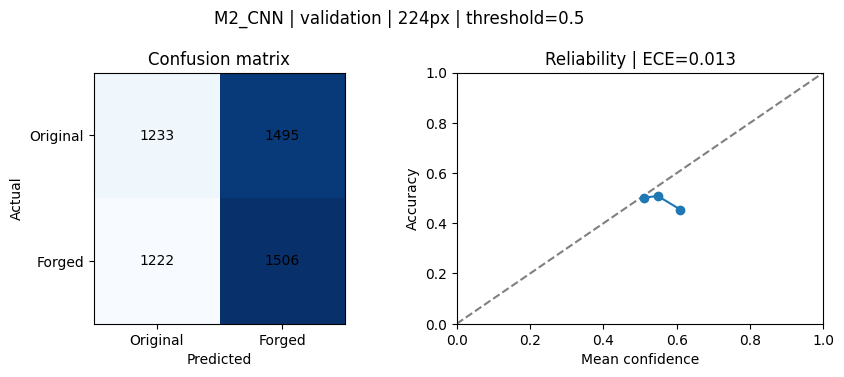

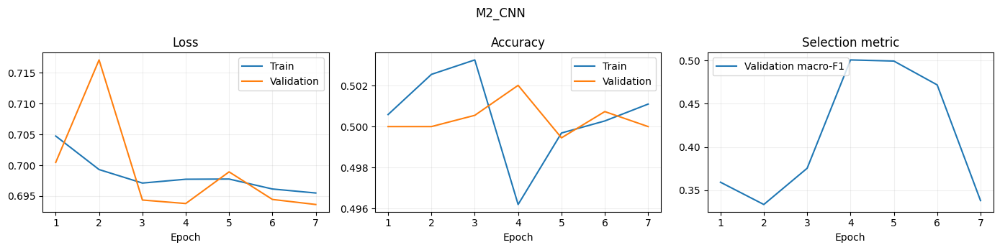

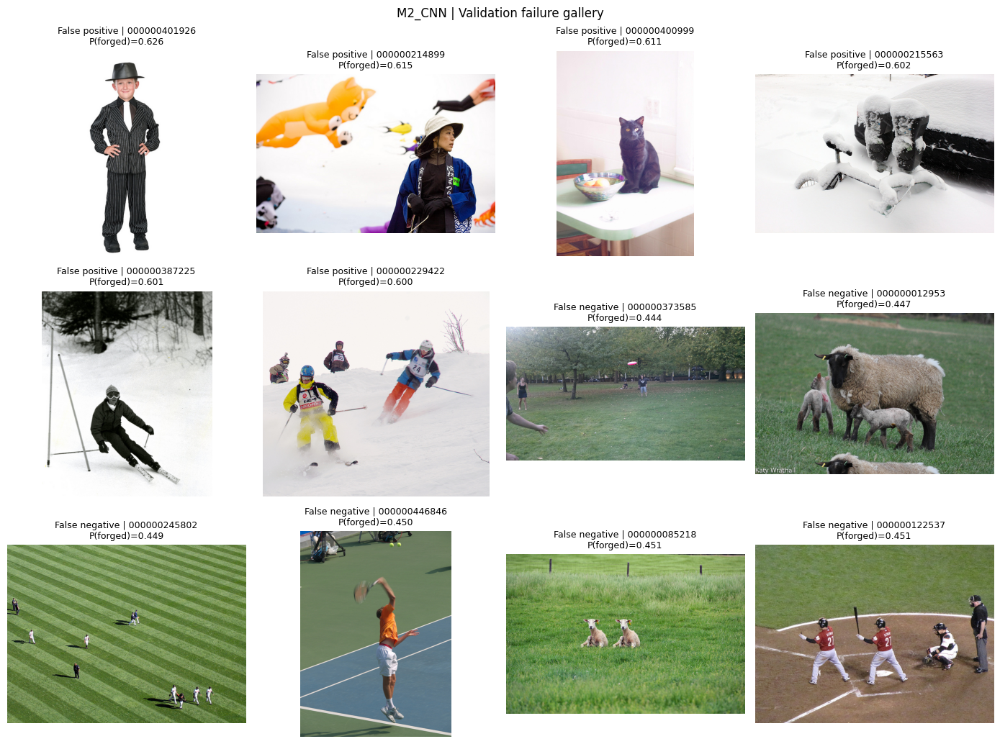

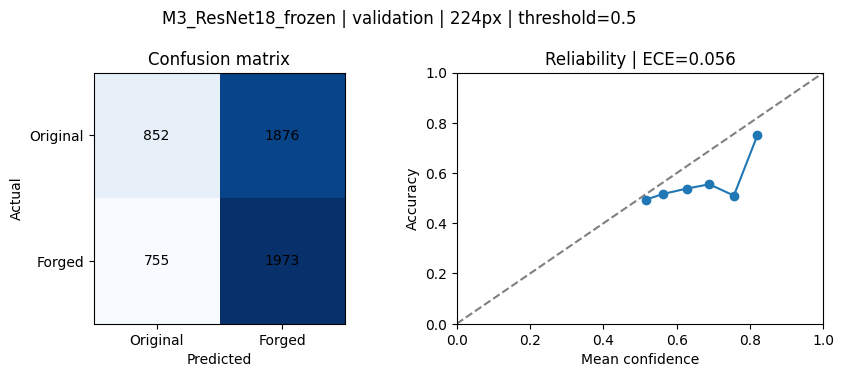

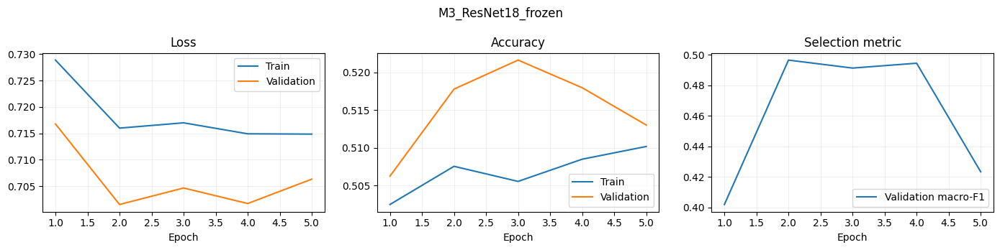

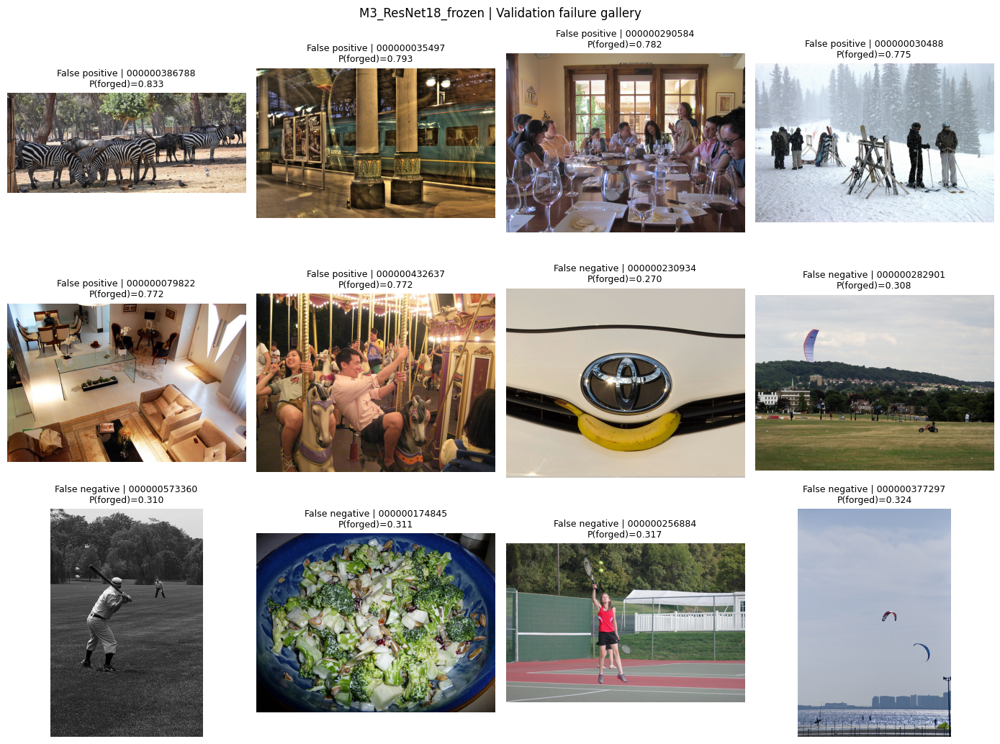

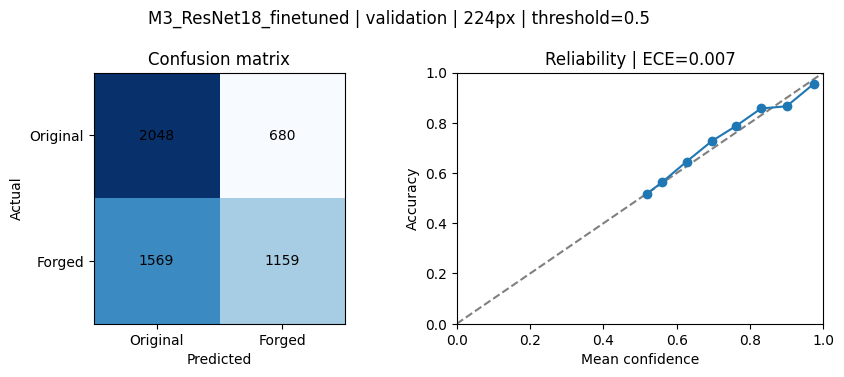

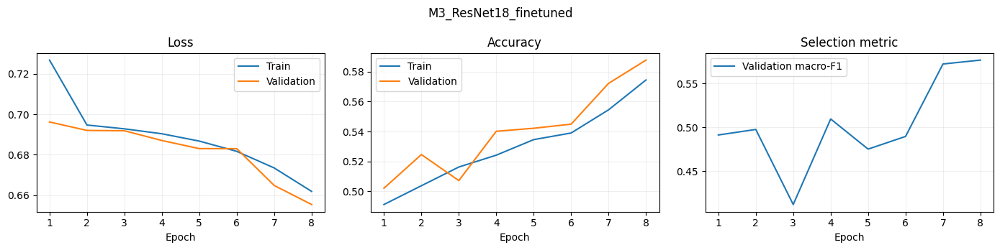

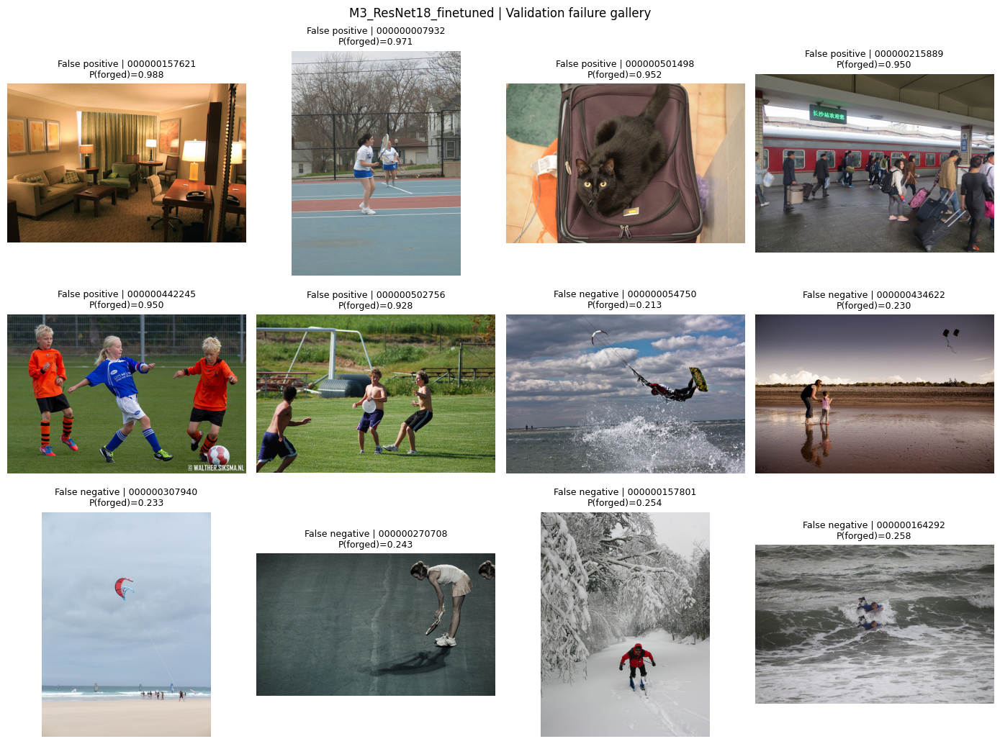

,model,accuracy,macro_f1,forged_recall,ece,roc_auc
0,M2_CNN,0.502016,0.500766,0.552053,0.012533,0.503031
1,M3_ResNet18_frozen,0.517779,0.496525,0.723240,0.055843,0.532083
2,M3_ResNet18_finetuned,0.587793,0.576551,0.424853,0.007433,0.632037


Selected BEFORE test evaluation: M3_ResNet18_finetuned


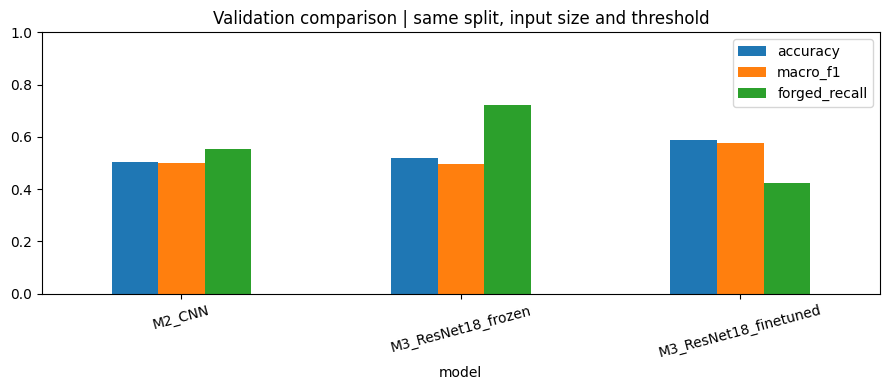

In [24]:
CHECKPOINTS = {'M2_CNN': M2_CHECKPOINT, 'M3_ResNet18_frozen': FROZEN_CHECKPOINT,
               'M3_ResNet18_finetuned': FINETUNE_CHECKPOINT}
validation_rows = []
for tag, path in CHECKPOINTS.items():
    model = load_best(tag, path)
    labels, probs, loss = predict(model, val_loader)
    metrics = save_evaluation(tag, 'validation', val_df, labels, probs, loss)
    validation_rows.append({'model': tag, **metrics})
    save_learning_curves(tag)
    validation_errors(tag, val_df, labels, probs)
    del model; gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()

VALIDATION_COMPARISON = pd.DataFrame(validation_rows)
VALIDATION_COMPARISON.to_csv(OUTPUT_DIR / 'validation_comparison.csv', index=False)
WINNER = str(VALIDATION_COMPARISON.loc[VALIDATION_COMPARISON['macro_f1'].idxmax(), 'model'])
write_json(OUTPUT_DIR / 'validation_selection.json', {'selected_model': WINNER,
    'criterion': 'validation macro-F1', 'threshold': CFG['threshold'], 'data_id': DATA_ID,
    'test_used_for_selection': False})
display(VALIDATION_COMPARISON[['model', 'accuracy', 'macro_f1', 'forged_recall', 'ece', 'roc_auc']])
print('Selected BEFORE test evaluation:', WINNER)
fig, ax = plt.subplots(figsize=(9, 4))
VALIDATION_COMPARISON.set_index('model')[['accuracy', 'macro_f1', 'forged_recall']].plot.bar(ax=ax, ylim=(0, 1), rot=15)
ax.set_title('Validation comparison | same split, input size and threshold')
fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'validation_comparison.png', dpi=150)
plt.show(); plt.close(fig)


## Shared — Step 15: Final test and compression stress evaluation

Evaluate each fixed checkpoint once on held-out test data, then on the same test images re-encoded at fixed JPEG quality 90. Cache predictions to avoid repeated inference; require matching checkpoint/data/preprocessing signatures. Do not choose models or retune using either test result.

نقيّم النماذج المختارة مسبقًا على Test، ثم اختبار ضغط JPEG محدد مسبقًا. نحفظ التوقعات ولا نستخدم الاختبار لتغيير النماذج. اختلاف النتائج تحت الضغط مؤشر يحتاج تفسيرًا وليس دليلًا وحده على سبب الخطأ.


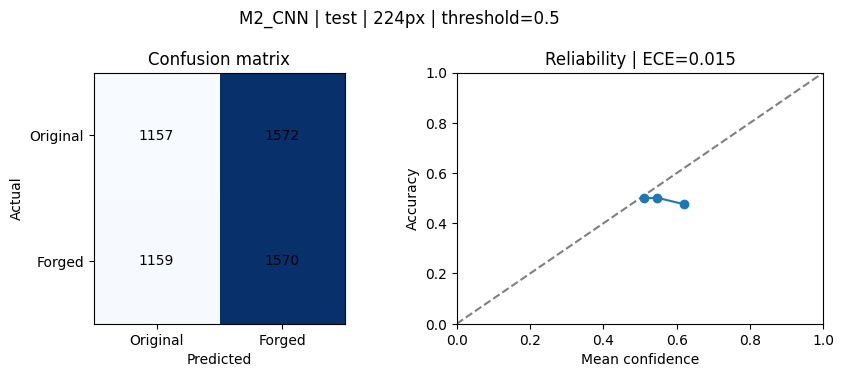

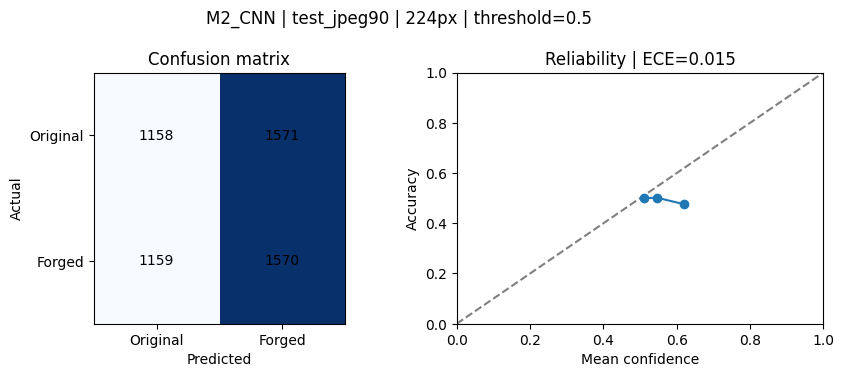

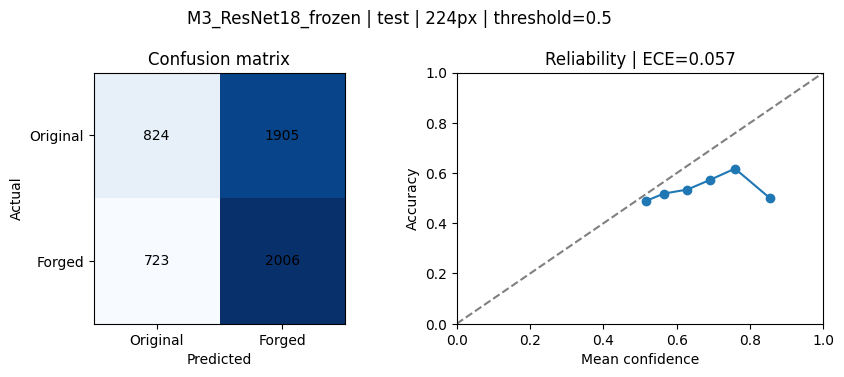

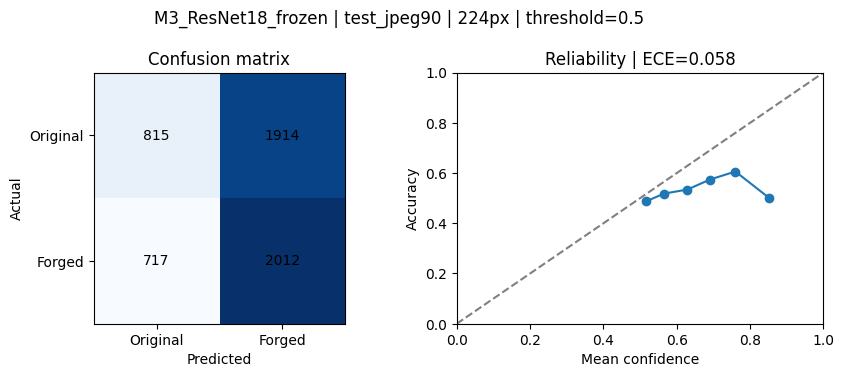

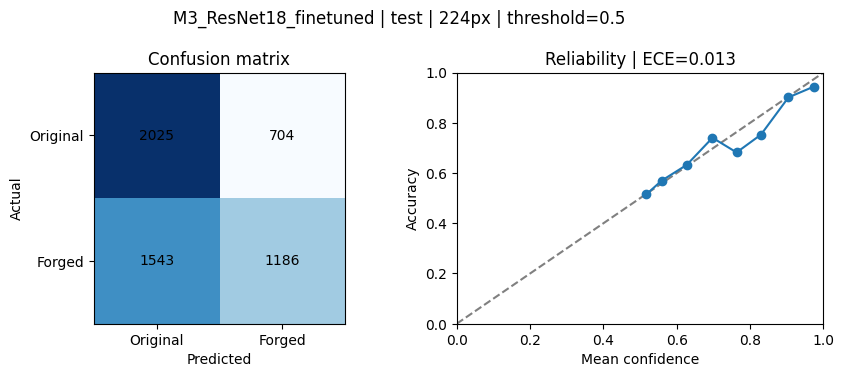

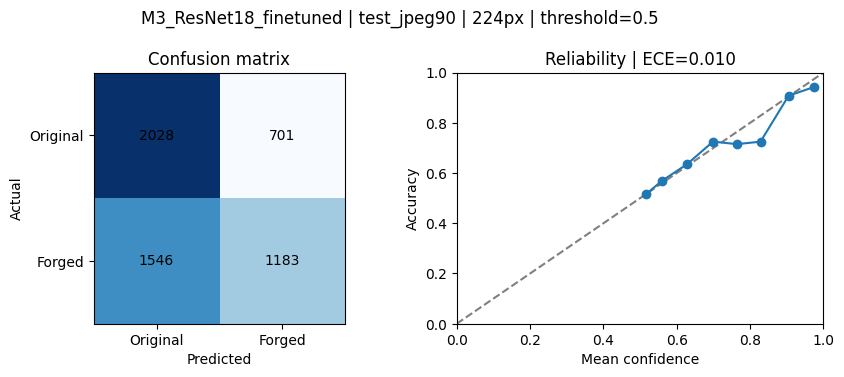

,model,accuracy,macro_f1,accuracy_ci95_low,accuracy_ci95_high,ece
0,M2_CNN,0.499634,0.496752,0.497618,0.501466,0.014849
1,M3_ResNet18_frozen,0.518505,0.494812,0.514291,0.523085,0.057473
2,M3_ResNet18_finetuned,0.588311,0.578347,0.580799,0.596006,0.012527


Preselected model remains: M3_ResNet18_finetuned
Top-2 accuracy is always 100% for two classes; it is not a useful performance claim.


In [25]:
test_rows, stress_rows = [], []
for tag, path in CHECKPOINTS.items():
    model = None
    signature = hashlib.sha256((file_sha256(path) + DATA_ID + json.dumps({
        'size': CFG['image_size'], 'threshold': CFG['threshold'], 'quality': CFG['jpeg_stress_quality'],
        'mean': MEAN, 'std': STD, 'version': '2026-10-29-v2'})).encode()).hexdigest()
    for split_name, jpeg_quality, rows in [('test', None, test_rows),
        ('test_jpeg90', CFG['jpeg_stress_quality'], stress_rows)]:
        folder = OUTPUT_DIR / tag
        cache_path = folder / f'{split_name}_inference.npz'
        meta_path = folder / f'{split_name}_inference_meta.json'
        if cache_path.exists() and meta_path.exists():
            assert json.loads(meta_path.read_text())['signature'] == signature, 'Test cache mismatch; do not silently overwrite final results.'
            with np.load(cache_path) as cached:
                labels, probs, loss = cached['labels'], cached['probs'], float(cached['loss'])
        else:
            if model is None: model = load_best(tag, path)
            labels, probs, loss = predict(model, make_loader(test_df, jpeg_quality=jpeg_quality))
            np.savez_compressed(cache_path, labels=labels, probs=probs, loss=loss)
            write_json(meta_path, {'signature': signature, 'data_id': DATA_ID})
        metrics = save_evaluation(tag, split_name, test_df, labels, probs, loss)
        rows.append({'model': tag, **metrics})
    if model is not None: del model
    gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()

TEST_COMPARISON = pd.DataFrame(test_rows)
STRESS_COMPARISON = pd.DataFrame(stress_rows)
TEST_COMPARISON.to_csv(OUTPUT_DIR / 'final_test_comparison.csv', index=False)
STRESS_COMPARISON.to_csv(OUTPUT_DIR / 'jpeg90_stress_comparison.csv', index=False)
display(TEST_COMPARISON[['model', 'accuracy', 'macro_f1', 'accuracy_ci95_low', 'accuracy_ci95_high', 'ece']])
print('Preselected model remains:', WINNER)
print('Top-2 accuracy is always 100% for two classes; it is not a useful performance claim.')


## Shared — Step 16: W&B comparison, evidence and final export

Save real metrics, environment versions, checkpoints, limitations, and a review template. Log comparison tables to W&B. Export a ZIP without source dataset images. Complete the human analysis and sync offline runs before claiming submission readiness.

نحفظ النتائج الفعلية ومعلومات إعادة التشغيل ونصدر ملف ZIP. لا نكتب تحليلًا بشريًا أو اعتمادًا لم يتم. أكمل ملاحظات تحليل الأخطاء وراجع M1 وزامن W&B قبل التسليم.


In [26]:
comparison_run = wandb.init(project=CFG['wandb_project'], entity=CFG['wandb_entity'],
    name='M2_M3_comparison', group=DATA_ID[:12], mode=CFG['wandb_mode'],
    dir=str(OUTPUT_DIR), config={'data_id': DATA_ID, 'selected_by': 'validation_macro_f1',
        'image_size': CFG['image_size'], 'threshold': CFG['threshold']})
try:
    comparison_run.log({'validation_comparison': wandb.Table(dataframe=VALIDATION_COMPARISON),
        'test_comparison': wandb.Table(dataframe=TEST_COMPARISON),
        'jpeg90_stress_comparison': wandb.Table(dataframe=STRESS_COMPARISON)})
    for tag in CHECKPOINTS:
        history = pd.read_csv(OUTPUT_DIR / tag / 'history.csv')
        for row in history.to_dict('records'):
            comparison_run.log({f'{tag}/{k}': v for k, v in row.items() if k != 'epoch'} | {f'{tag}/epoch': row['epoch']})
        for split_name, table in [('validation', VALIDATION_COMPARISON), ('test', TEST_COMPARISON)]:
            record = table.set_index('model').loc[tag].to_dict()
            for key, value in record.items():
                if isinstance(value, (int, float, np.number)):
                    comparison_run.summary[f'{tag}/{split_name}/{key}'] = float(value)
    comparison_run.summary['validation_selected_model'] = WINNER
    comparison_url = comparison_run.url if CFG['wandb_mode'] == 'online' else None
finally:
    comparison_run.finish()

packages = {}
for package in ['torch', 'torchvision', 'numpy', 'pandas', 'Pillow', 'scikit-learn', 'matplotlib', 'wandb', 'tqdm']:
    try: packages[package] = version(package)
    except PackageNotFoundError: pass
(OUTPUT_DIR / 'requirements_snapshot.txt').write_text('\n'.join(f'{k}=={v}' for k, v in packages.items()) + '\n')
environment = {'python': sys.version, 'packages': packages, 'device': str(DEVICE),
    'gpu': torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else None,
    'cuda': torch.version.cuda, 'created_utc': datetime.now(timezone.utc).isoformat()}
write_json(OUTPUT_DIR / 'environment.json', environment)
offline_dirs = sorted(str(p) for p in OUTPUT_DIR.rglob('offline-run-*') if p.is_dir())
sync_commands = ['wandb login'] + [f'wandb sync "{p}"' for p in offline_dirs]
(OUTPUT_DIR / 'wandb_sync_commands.txt').write_text('\n'.join(sync_commands) + '\n')
write_json(OUTPUT_DIR / 'experiment_report.json', {
    'project': 'ForgeryGuard AI', 'milestones': ['M2', 'M3'], 'source_pairs': len(MANIFEST),
    'source_images': len(DATA_RAW), 'effective_images': len(DATA), 'data_id': DATA_ID,
    'split_strategy': 'M1 source assignments preserved; same-split exact duplicates excluded',
    'pixel_hash_conflicts': len(conflict_hashes), 'exact_cross_split_hashes': len(leak_hashes),
    'config': CFG, 'selected_model': WINNER, 'selection_metric': 'validation macro-F1',
    'validation': VALIDATION_COMPARISON.to_dict('records'), 'test': TEST_COMPARISON.to_dict('records'),
    'jpeg90_stress': STRESS_COMPARISON.to_dict('records'),
    'visual_review': review_record, 'wandb_comparison_url': comparison_url,
    'offline_runs_to_sync': offline_dirs, 'test_used_for_selection': False,
    'readiness': 'Technical results generated; M1 manual reviews and human error analysis remain required'})

analysis_path = OUTPUT_DIR / 'error_analysis_and_data_plan.md'
if not analysis_path.exists():
    analysis_path.write_text(
        '# Validation error analysis and data-improvement plan\n\n'
        'Status: PENDING HUMAN REVIEW. Do not submit this template as completed analysis.\n\n'
        'For each model, inspect validation_errors.csv and validation_failure_gallery.png.\n'
        '- Cite at least one false positive or false negative by source_group.\n'
        '- Describe the visible failure, confidence, and evidence; distinguish hypotheses from facts.\n'
        '- Check whether small tampered regions were lost at 224px.\n'
        '- Discuss JPG/TIFF compression differences and the fixed JPEG stress results.\n'
        '- Propose one targeted data improvement per observed failure pattern.\n'
        '- Do not retune on held-out test results. Changes require a future, fresh evaluation.\n'
        '- Record remaining privacy/license checks and sampling limitations.\n', encoding='utf-8')

selected_validation = VALIDATION_COMPARISON.set_index('model').loc[WINNER]
selected_test = TEST_COMPARISON.set_index('model').loc[WINNER]
summary = f"""# ForgeryGuard AI — M2/M3 results

Selected by validation macro-F1: **{WINNER}**.

- Source pairs: {len(MANIFEST):,}; source images: {len(DATA_RAW):,}; effective images: {len(DATA):,}.
- Input: {CFG['image_size']}×{CFG['image_size']}, RGB, ImageNet normalization; threshold {CFG['threshold']}.
- Selected validation macro-F1: {selected_validation['macro_f1']:.4f}.
- Selected test accuracy: {selected_test['accuracy']:.4f}; macro-F1: {selected_test['macro_f1']:.4f}.
- Test accuracy 95% source-group bootstrap interval: [{selected_test['accuracy_ci95_low']:.4f}, {selected_test['accuracy_ci95_high']:.4f}].
- Test was not used to select the model; all three checkpoints are compared for reporting.

## Files
Each model folder contains best.pt, last.pt, history.csv, training_config.json, per-class reports,
predictions, confusion matrices, calibration plots, validation error galleries, and W&B logs.
The root contains comparisons, source/effective manifests, audit reports and environment/config snapshots.

## Required review before submission
- M1 licensing and privacy review remains as recorded in source_dataset_card.json.
- Visual sample completed: {VISUAL_REVIEW_COMPLETED}. Sample review is not full-dataset clearance.
- Complete error_analysis_and_data_plan.md with observations from actual validation failures.
- W&B mode: {CFG['wandb_mode']}. Offline runs must be synced to produce the online comparison.
- M1 label-error statistical audit is not completed by this M2/M3 notebook.

## Limitations
Exact RGB hashes do not guarantee absence of near-duplicate scenes. Original JPG vs forged TIFF
can create an encoding shortcut; identical RGB loading and JPEG stress do not prove it is removed.
Resize224 can hide small manipulation traces. Calibration is measured without post-hoc calibration.
Bootstrap intervals assume independent source groups, not arbitrary independent image rows.
No M4/M5/M8 work or deployment-readiness claim is made here.

## Kaggle persistence
Save a notebook version with outputs and verify the Output tab. Save & Run All starts a fresh session.
For later resume, attach that saved notebook output and set resume_from_dir to its result folder.
Do not publish source data, private images, credentials, or unreviewed galleries.
"""
(OUTPUT_DIR / 'RESULTS_README.md').write_text(summary, encoding='utf-8')

# Archive result artifacts, not the source datasets or pretrained ImageNet weights.
archive = Path('/kaggle/working/ForgeryGuard_AI_M2_M3_results.zip')
shutil.make_archive(str(archive.with_suffix('')), 'zip', root_dir=OUTPUT_DIR.parent, base_dir=OUTPUT_DIR.name)
print('Technical run finished. Review pending items in RESULTS_README.md.')
print('Results folder:', OUTPUT_DIR)
print('ZIP:', archive)
print('W&B mode:', CFG['wandb_mode'], '| Offline folders to sync:', len(offline_dirs))
print('Save a Kaggle version with outputs; check that best.pt and the ZIP appear in Output.')


M2_CNN/epoch,▁▂▃▅▆▇█
M2_CNN/epoch_seconds,▄▁▃▆▇█▆
M2_CNN/train_accuracy,▅▇█▁▄▅▆
M2_CNN/train_loss,█▄▂▃▃▁▁
M2_CNN/val_accuracy,▃▃▄█▁▅▃
M2_CNN/val_balanced_accuracy,▃▃▄█▁▅▃
M2_CNN/val_ece,▅█▂▁▃▂▁
M2_CNN/val_forged_f1,▁██▆▆▇█
M2_CNN/val_forged_precision,▃▃▃█▁▄▃
M2_CNN/val_forged_recall,▁██▅▄▆█
+50,...


Technical run finished. Review pending items in RESULTS_README.md.
Results folder: /kaggle/working/ForgeryGuard_AI_M2_M3
ZIP: /kaggle/working/ForgeryGuard_AI_M2_M3_results.zip
W&B mode: offline | Offline folders to sync: 4
Save a Kaggle version with outputs; check that best.pt and the ZIP appear in Output.


## Shared — Step 17: Final Model Comparison

استخراج نتائج النماذج الثلاثة من الملفات المحفوظة في Kaggle، وعرض مقاييس الأداء للمقارنة دون إعادة التدريب أو تعديل النتائج.

Extract the saved evaluation metrics for all three models from Kaggle and compare their performance without retraining or modifying results.

In [32]:

from pathlib import Path
import pandas as pd

# تحديد مجلد النتائج
RESULTS_DIR = Path(
    "/kaggle/working/ForgeryGuard_AI_M2_M3"
)

# البحث عن ملفات المقارنة والنتائج
files = sorted(
    p for p in RESULTS_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in [".csv", ".json"]
    and any(
        word in p.name.lower()
        for word in ["comparison", "metrics", "summary"]
    )
)

print("========== SAVED EVALUATION FILES ==========")

for i, file in enumerate(files, 1):
    print(f"{i}. {file.relative_to(RESULTS_DIR)}")

# عرض ملفات المقارنة الموجودة
for file in files:
    if "comparison" in file.name.lower():
        print(f"\n========== {file.name} ==========")

        if file.suffix.lower() == ".csv":
            display(pd.read_csv(file))
        else:
            print(file.read_text(encoding="utf-8")[:5000])


========== SAVED EVALUATION FILES ==========
1. M2_CNN/test_jpeg90_metrics.json
2. M2_CNN/test_metrics.json
3. M2_CNN/validation_metrics.json
4. M2_CNN/wandb/offline-run-20261029_104543-swgfffwc/files/wandb-summary.json
5. M3_ResNet18_finetuned/test_jpeg90_metrics.json
6. M3_ResNet18_finetuned/test_metrics.json
7. M3_ResNet18_finetuned/validation_metrics.json
8. M3_ResNet18_finetuned/wandb/offline-run-20261029_111705-o8mw82oe/files/wandb-summary.json
9. M3_ResNet18_frozen/test_jpeg90_metrics.json
10. M3_ResNet18_frozen/test_metrics.json
11. M3_ResNet18_frozen/validation_metrics.json
12. M3_ResNet18_frozen/wandb/offline-run-20261029_110406-2di9i06z/files/wandb-summary.json
13. final_test_comparison.csv
14. jpeg90_stress_comparison.csv
15. validation_comparison.csv
16. wandb/offline-run-20261029_114313-qnibs4sc/files/media/table/jpeg90_stress_comparison_0_c758ccc923921eee7095.table.json
17. wandb/offline-run-20261029_114313-qnibs4sc/files/media/table/test_comparison_0_bd8c299ce6e39f106de

,model,accuracy,macro_f1,balanced_accuracy,ece,roc_auc,threshold,top2_accuracy,original_precision,original_recall,...,original_support,forged_precision,forged_recall,forged_f1,forged_support,loss,accuracy_ci95_low,accuracy_ci95_high,ci_method,ci_repeats
0,M2_CNN,0.499634,0.496752,0.499634,0.014849,0.501885,0.5,1.0,0.499568,0.423965,...,2729,0.499682,0.575302,0.534832,2729,0.693897,0.497618,0.501466,source-group bootstrap,2000
1,M3_ResNet18_frozen,0.518505,0.494812,0.518505,0.057473,0.534618,0.5,1.0,0.532644,0.301942,...,2729,0.512912,0.735068,0.604217,2729,0.700929,0.514291,0.523085,source-group bootstrap,2000
2,M3_ResNet18_finetuned,0.588311,0.578347,0.588311,0.012527,0.633941,0.5,1.0,0.567545,0.742030,...,2729,0.627513,0.434591,0.513531,2729,0.658240,0.580799,0.596006,source-group bootstrap,2000



========== jpeg90_stress_comparison.csv ==========


,model,accuracy,macro_f1,balanced_accuracy,ece,roc_auc,threshold,top2_accuracy,original_precision,original_recall,...,original_support,forged_precision,forged_recall,forged_f1,forged_support,loss,accuracy_ci95_low,accuracy_ci95_high,ci_method,ci_repeats
0,M2_CNN,0.499817,0.496950,0.499817,0.014652,0.501873,0.5,1.0,0.499784,0.424331,...,2729,0.499841,0.575302,0.534923,2729,0.693892,0.497797,0.501832,source-group bootstrap,2000
1,M3_ResNet18_frozen,0.517955,0.493599,0.517955,0.058128,0.534666,0.5,1.0,0.531984,0.298644,...,2729,0.512481,0.737266,0.604658,2729,0.700963,0.513741,0.522353,source-group bootstrap,2000
2,M3_ResNet18_finetuned,0.588311,0.578201,0.588311,0.010004,0.633960,0.5,1.0,0.567431,0.743129,...,2729,0.627919,0.433492,0.512898,2729,0.658203,0.580982,0.596189,source-group bootstrap,2000



========== validation_comparison.csv ==========


,model,accuracy,macro_f1,balanced_accuracy,ece,roc_auc,threshold,top2_accuracy,original_precision,original_recall,...,original_support,forged_precision,forged_recall,forged_f1,forged_support,loss,accuracy_ci95_low,accuracy_ci95_high,ci_method,ci_repeats
0,M2_CNN,0.502016,0.500766,0.502016,0.012533,0.503031,0.5,1.0,0.502240,0.451979,...,2728,0.501833,0.552053,0.525746,2728,0.693799,0.500183,0.503849,source-group bootstrap,2000
1,M3_ResNet18_frozen,0.517779,0.496525,0.517779,0.055843,0.532083,0.5,1.0,0.530180,0.312317,...,2728,0.512601,0.723240,0.599970,2728,0.701514,0.513013,0.522727,source-group bootstrap,2000
2,M3_ResNet18_finetuned,0.587793,0.576551,0.587793,0.007433,0.632037,0.5,1.0,0.566215,0.750733,...,2728,0.630234,0.424853,0.507554,2728,0.655432,0.580462,0.595674,source-group bootstrap,2000



========== jpeg90_stress_comparison_0_c758ccc923921eee7095.table.json ==========
{"columns":["model","accuracy","macro_f1","balanced_accuracy","ece","roc_auc","threshold","top2_accuracy","original_precision","original_recall","original_f1","original_support","forged_precision","forged_recall","forged_f1","forged_support","loss","accuracy_ci95_low","accuracy_ci95_high","ci_method","ci_repeats"],"data":[["M2_CNN",0.4998167827042873,0.4969503734298626,0.4998167827042873,0.014651812233519468,0.5018731937587689,0.5,1.0,0.4997842037116962,0.4243312568706486,0.4589774078478002,2729,0.49984081502706146,0.575302308537926,0.534923339011925,2729,0.6938917160514686,0.4977968120190546,0.5018321729571271,"source-group bootstrap",2000],["M3_ResNet18_frozen",0.517955294979846,0.4935987308933558,0.5179552949798462,0.05812780275946355,0.5346655314221355,0.5,1.0,0.5319843342036553,0.29864419201172593,0.3825393100211218,2729,0.5124808965868568,0.7372663979479663,0.6046581517655898,2729,0.700962937415498,

## Shared — Step 18: Test Error Analysis
تحليل أخطاء النموذج الأفضل باستخدام تنبؤات مجموعة الاختبار المحفوظة. نحسب مصفوفة الالتباس وعدد الحالات الصحيحة والخاطئة، ونستخرج عينات من False Positives وFalse Negatives لمراجعتها لاحقًا، دون تعديل نتائج النموذج أو إعادة تدريبه.

Analyze the best model using saved test predictions. Calculate the confusion matrix, count correct and incorrect classifications, and extract false-positive and false-negative examples for subsequent human review without retraining or modifying model results.

In [35]:

from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix

# تحديد ملفات نتائج النموذج الأفضل
MODEL_DIR = Path(
    "/kaggle/working/ForgeryGuard_AI_M2_M3/"
    "M3_ResNet18_finetuned"
)

PREDICTIONS_PATH = MODEL_DIR / "test_predictions.csv"

# قراءة التنبؤات المحفوظة
df = pd.read_csv(PREDICTIONS_PATH)

print("Available columns:", df.columns.tolist())
print("Total predictions:", len(df))

# تحديد أسماء الأعمدة المتاحة
def find_column(options):
    for name in options:
        if name in df.columns:
            return name
    return None

true_col = find_column([
    "true_label", "label", "y_true", "target"
])

pred_col = find_column([
    "predicted_label", "prediction",
    "pred_label", "y_pred"
])

if true_col is None or pred_col is None:
    print("\nColumn names need verification.")
    display(df.head(5))
else:
    # حساب مصفوفة الالتباس
    y_true = df[true_col].astype(int)
    y_pred = df[pred_col].astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    print("\n========== TEST ERROR ANALYSIS ==========")
    print("True Negatives:", tn)
    print("False Positives:", fp)
    print("False Negatives:", fn)
    print("True Positives:", tp)

    print("\nTotal errors:", fp + fn)
    print("Accuracy:", round((tp + tn) / len(df), 4))

    # استخراج الأخطاء لمراجعتها
    false_positives = df[
        (y_true == 0) & (y_pred == 1)
    ]

    false_negatives = df[
        (y_true == 1) & (y_pred == 0)
    ]

    print("\nFalse Positive examples:")
    display(false_positives.head(10))

    print("\nFalse Negative examples:")
    display(false_negatives.head(10))

    # حفظ قوائم الأخطاء
    false_positives.to_csv(
        MODEL_DIR / "test_false_positives.csv",
        index=False
    )

    false_negatives.to_csv(
        MODEL_DIR / "test_false_negatives.csv",
        index=False
    )

    print("\nSTATUS: ERROR ANALYSIS COMPLETE")


Available columns: ['source_group', 'filename', 'label', 'forged_probability', 'prediction', 'correct']
Total predictions: 5458

========== TEST ERROR ANALYSIS ==========
True Negatives: 2025
False Positives: 704
False Negatives: 1543
True Positives: 1186

Total errors: 2247
Accuracy: 0.5883

False Positive examples:


,source_group,filename,label,forged_probability,prediction,correct
5,5064,000000005064.jpg,0,0.641450,1,False
8,7666,000000007666.jpg,0,0.674104,1,False
9,9041,000000009041.jpg,0,0.584004,1,False
13,10719,000000010719.jpg,0,0.516260,1,False
16,11774,000000011774.jpg,0,0.542969,1,False
24,19236,000000019236.jpg,0,0.788420,1,False
26,21592,000000021592.jpg,0,0.548311,1,False
27,22164,000000022164.jpg,0,0.524151,1,False
28,24154,000000024154.jpg,0,0.742001,1,False
35,27826,000000027826.jpg,0,0.502350,1,False



False Negative examples:


,source_group,filename,label,forged_probability,prediction,correct
2729,71,0_000000000071.tif,1,0.443329,0,False
2732,3764,0_000000003764.tif,1,0.444294,0,False
2733,4622,0_000000004622.tif,1,0.431554,0,False
2735,5802,0_000000005802.tif,1,0.472235,0,False
2736,6539,0_000000006539.tif,1,0.411185,0,False
2740,9170,0_000000009170.tif,1,0.493561,0,False
2741,10540,0_000000010540.tif,1,0.382055,0,False
2743,10948,0_000000010948.tif,1,0.444226,0,False
2746,12673,0_000000012673.tif,1,0.487338,0,False
2747,12833,0_000000012833.tif,1,0.417182,0,False



STATUS: ERROR ANALYSIS COMPLETE


## Shared — Step 19: Calibration, ECE & 95% CI

حساب فاصل الثقة 95% لدقة الاختبار وExpected Calibration Error (ECE)، وإنشاء Reliability Diagram للنموذجين باستخدام التنبؤات المحفوظة فقط. تُحفظ النتائج في ملفات قابلة للاستخدام داخل تقرير Phase 1، دون إعادة تدريب النماذج.

Calculate the 95% confidence interval for test accuracy and Expected Calibration Error (ECE), and generate reliability diagrams for both models using saved predictions only. Export the results for the Phase 1 report without retraining the models.

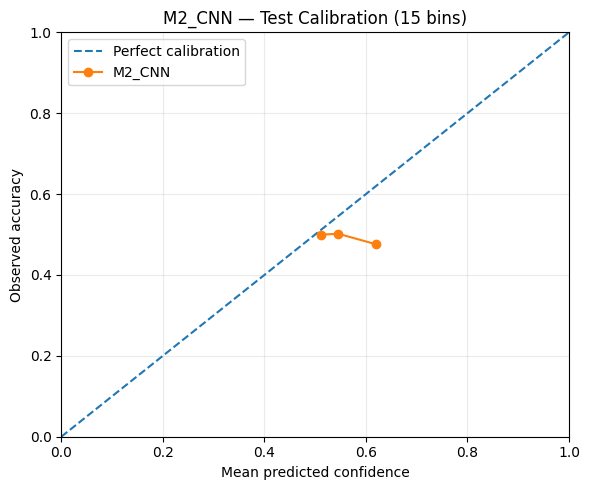


========== M2_CNN ==========
Accuracy: 0.4996
95% CI: [0.4864, 0.5129]
ECE (15 bins): 0.0148


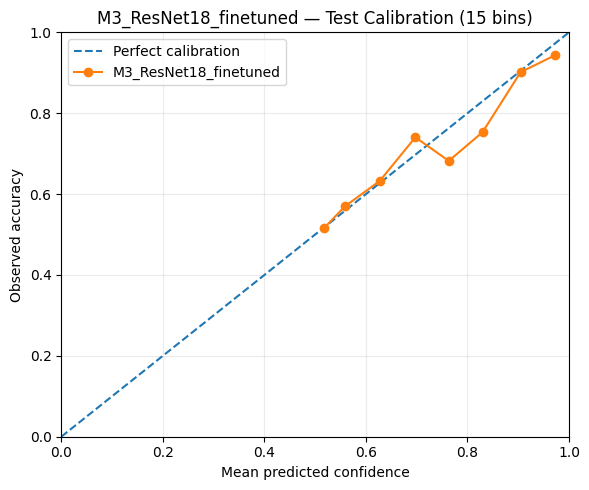


========== M3_ResNet18_finetuned ==========
Accuracy: 0.5883
95% CI: [0.5752, 0.6013]
ECE (15 bins): 0.0125

STATUS: CALIBRATION ANALYSIS COMPLETE


,model,split,samples,accuracy,ci95_lower,ci95_upper,ece_15_bins
0,M2_CNN,test,5458,0.499634,0.486373,0.512894,0.014849
1,M3_ResNet18_finetuned,test,5458,0.588311,0.575197,0.601301,0.012527


In [36]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from math import sqrt

# تحديد مسارات النتائج المحفوظة
ROOT = Path("/kaggle/working/ForgeryGuard_AI_M2_M3")
OUTPUT = ROOT / "Phase1_Report_Figures"
OUTPUT.mkdir(parents=True, exist_ok=True)

MODELS = {
    "M2_CNN": ROOT / "M2_CNN" / "test_predictions.csv",
    "M3_ResNet18_finetuned": (
        ROOT / "M3_ResNet18_finetuned" / "test_predictions.csv"
    )
}

# حساب فاصل الثقة بطريقة Wilson
def wilson_interval(correct, total, z=1.96):
    p = correct / total
    denominator = 1 + z**2 / total
    center = (p + z**2 / (2 * total)) / denominator
    margin = (
        z * sqrt(p * (1 - p) / total + z**2 / (4 * total**2))
        / denominator
    )
    return center - margin, center + margin

# حساب ECE ورسم مخطط المعايرة
def calibration_analysis(df, model_name, bins=15):
    labels = df["label"].to_numpy(dtype=int)
    predictions = df["prediction"].to_numpy(dtype=int)
    probabilities = df["forged_probability"].to_numpy(dtype=float)

    if not np.all(np.isfinite(probabilities)):
        raise ValueError("Invalid probability values found")

    if np.any((probabilities < 0) | (probabilities > 1)):
        raise ValueError("Probabilities must be between 0 and 1")

    # حساب الثقة في الفئة المتوقعة
    confidence = np.where(
        predictions == 1, probabilities, 1 - probabilities
    )
    correctness = (predictions == labels).astype(float)

    edges = np.linspace(0, 1, bins + 1)
    bin_ids = np.minimum(
        np.digitize(confidence, edges[1:-1]), bins - 1
    )

    ece = 0.0
    points_x = []
    points_y = []

    for index in range(bins):
        mask = bin_ids == index
        count = mask.sum()

        if count == 0:
            continue

        avg_confidence = confidence[mask].mean()
        avg_accuracy = correctness[mask].mean()

        ece += (count / len(df)) * abs(
            avg_accuracy - avg_confidence
        )

        points_x.append(avg_confidence)
        points_y.append(avg_accuracy)

    # إنشاء الشكل وحفظه
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot([0, 1], [0, 1], "--", label="Perfect calibration")
    ax.plot(
        points_x, points_y, "o-",
        label=model_name
    )
    ax.set(
        xlabel="Mean predicted confidence",
        ylabel="Observed accuracy",
        title=f"{model_name} — Test Calibration (15 bins)",
        xlim=(0, 1),
        ylim=(0, 1)
    )
    ax.legend()
    ax.grid(alpha=0.25)

    fig.tight_layout()
    fig.savefig(
        OUTPUT / f"{model_name}_reliability.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    return ece

results = []

for model_name, path in MODELS.items():
    if not path.exists():
        print(f"Missing predictions: {path}")
        continue

    df = pd.read_csv(path)

    required = {"label", "prediction", "forged_probability"}
    if not required.issubset(df.columns):
        print(f"Missing required columns: {model_name}")
        continue

    total = len(df)
    correct = int((df["label"] == df["prediction"]).sum())

    accuracy = accuracy_score(df["label"], df["prediction"])
    ci_low, ci_high = wilson_interval(correct, total)
    ece = calibration_analysis(df, model_name)

    results.append({
        "model": model_name,
        "split": "test",
        "samples": total,
        "accuracy": accuracy,
        "ci95_lower": ci_low,
        "ci95_upper": ci_high,
        "ece_15_bins": ece
    })

    print(f"\n========== {model_name} ==========")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"95% CI: [{ci_low:.4f}, {ci_high:.4f}]")
    print(f"ECE (15 bins): {ece:.4f}")

if results:
    summary = pd.DataFrame(results)
    summary.to_csv(
        OUTPUT / "calibration_ci_summary.csv",
        index=False
    )
    print("\nSTATUS: CALIBRATION ANALYSIS COMPLETE")
    display(summary)


## Shared — Step 20: Visual Error Gallery

إنشاء معرض بصري لأخطاء تصنيف نموذج ResNet18 Fine-Tuned باستخدام تنبؤات مجموعة الاختبار المحفوظة. يعرض المعرض عينات من الصور المزورة التي لم يكتشفها النموذج (False Negatives)، والصور الأصلية التي صنفها خطأ على أنها مزورة (False Positives)، مع عرض أقنعة التزوير المتاحة. تُحفظ الصور لاستخدامها في تقرير Phase 1 دون إعادة تدريب النموذج.

Generate a visual error gallery for the fine-tuned ResNet18 model using saved test predictions. Display examples of missed forgeries (False Negatives) and original images incorrectly flagged as forged (False Positives), including available forgery masks. Export the figures for the Phase 1 report without retraining.

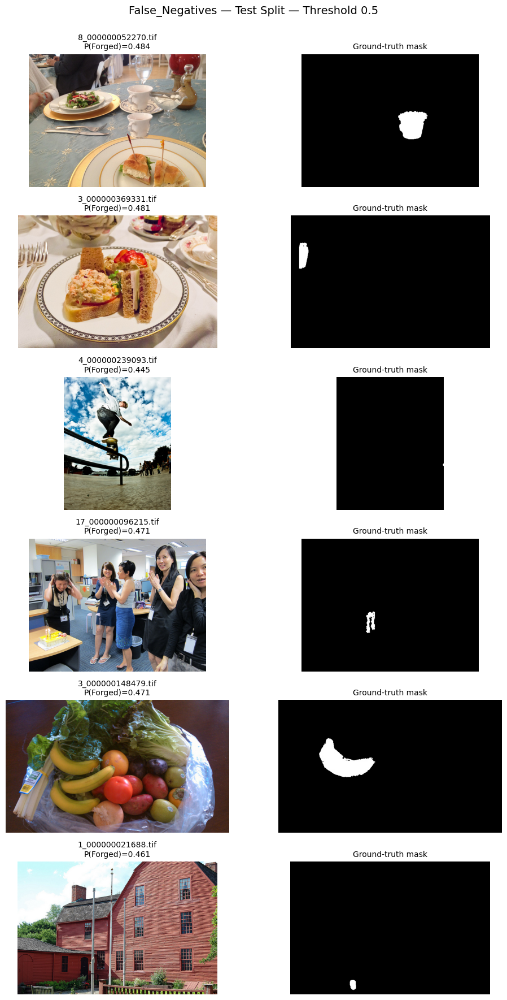

False_Negatives saved: /kaggle/working/ForgeryGuard_AI_M2_M3/Phase1_Report_Figures/false_negatives_gallery.png
Missing images: 0
Missing masks: 0


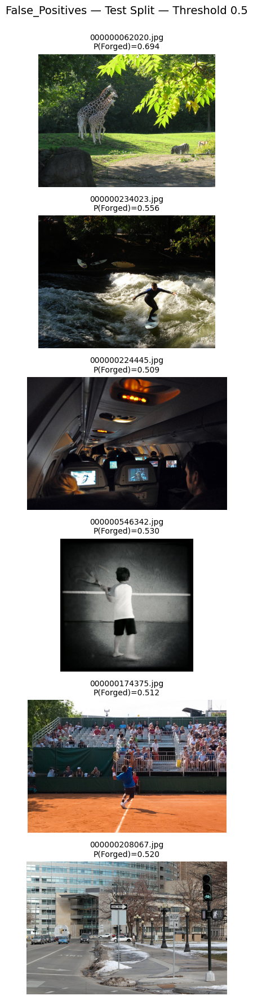

False_Positives saved: /kaggle/working/ForgeryGuard_AI_M2_M3/Phase1_Report_Figures/false_positives_gallery.png
Missing images: 0

STATUS: VISUAL ERROR GALLERY COMPLETE


In [38]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# تحديد مسارات البيانات والنتائج
ROOT = Path("/kaggle/working/ForgeryGuard_AI_M2_M3")
MODEL_DIR = ROOT / "M3_ResNet18_finetuned"
OUTPUT_DIR = ROOT / "Phase1_Report_Figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ORIGINAL_DIR = Path(
    "/kaggle/input/datasets/mkajrfi/forgeryguard-ai/"
    "forgeryguard_originals/Original"
)

DEFACTO_ROOT = Path(
    "/kaggle/input/datasets/defactodataset/defactocopymove"
)

FORGED_DIR = DEFACTO_ROOT / "copymove_img/img"
MASK_DIR = DEFACTO_ROOT / "copymove_annotations/probe_mask"

# قراءة تنبؤات الاختبار المحفوظة
df = pd.read_csv(MODEL_DIR / "test_predictions.csv")

# اختيار عينات ثابتة قابلة لإعادة الإنتاج
false_negatives = df[
    (df["label"] == 1) & (df["prediction"] == 0)
].sample(n=6, random_state=42)

false_positives = df[
    (df["label"] == 0) & (df["prediction"] == 1)
].sample(n=6, random_state=42)

# فتح الصورة مع التعامل مع الملفات غير المتاحة
def load_image(path):
    if not path.exists():
        return None
    try:
        with Image.open(path) as img:
            return img.convert("RGB").copy()
    except (OSError, ValueError):
        return None

# البحث عن القناع الموافق لاسم الصورة المزورة
def find_mask(filename):
    stem = Path(filename).stem

    candidates = [
        MASK_DIR / f"{stem}.png",
        MASK_DIR / f"{stem}.tif",
        MASK_DIR / f"{stem}.tiff",
        MASK_DIR / f"{stem}.jpg"
    ]

    for candidate in candidates:
        if candidate.exists():
            return candidate

    return None

# إنشاء معرض لكل نوع من الأخطاء
def create_gallery(samples, error_type, image_dir, with_masks):
    columns = 2 if with_masks else 1
    fig, axes = plt.subplots(
        len(samples),
        columns,
        figsize=(10 if with_masks else 6, 3 * len(samples)),
        squeeze=False
    )

    missing_images = 0
    missing_masks = 0

    for row_index, (_, record) in enumerate(samples.iterrows()):
        filename = record["filename"]
        image_path = image_dir / filename
        image = load_image(image_path)

        ax = axes[row_index, 0]
        ax.axis("off")

        if image is None:
            missing_images += 1
            ax.text(
                0.5, 0.5, "Image unavailable",
                ha="center", va="center"
            )
        else:
            ax.imshow(image)

        ax.set_title(
            f"{filename}\n"
            f"P(Forged)={record['forged_probability']:.3f}",
            fontsize=10
        )

        if with_masks:
            mask_ax = axes[row_index, 1]
            mask_ax.axis("off")

            mask_path = find_mask(filename)

            if mask_path is None:
                missing_masks += 1
                mask_ax.text(
                    0.5, 0.5, "Mask unavailable",
                    ha="center", va="center"
                )
            else:
                mask = load_image(mask_path)

                if mask is None:
                    missing_masks += 1
                    mask_ax.text(
                        0.5, 0.5, "Mask unreadable",
                        ha="center", va="center"
                    )
                else:
                    mask_ax.imshow(mask)

            mask_ax.set_title("Ground-truth mask", fontsize=10)

    fig.suptitle(
        f"{error_type} — Test Split — Threshold 0.5",
        fontsize=14
    )
    fig.tight_layout(rect=[0, 0, 1, 0.98])

    output_path = OUTPUT_DIR / f"{error_type.lower()}_gallery.png"
    fig.savefig(output_path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"{error_type} saved: {output_path}")
    print(f"Missing images: {missing_images}")
    if with_masks:
        print(f"Missing masks: {missing_masks}")

# إنشاء معرض الصور المزورة غير المكتشفة
create_gallery(
    false_negatives,
    "False_Negatives",
    FORGED_DIR,
    with_masks=True
)

# إنشاء معرض الصور الأصلية المصنفة خطأ
create_gallery(
    false_positives,
    "False_Positives",
    ORIGINAL_DIR,
    with_masks=False
)

print("\nSTATUS: VISUAL ERROR GALLERY COMPLETE")


## Shared — Step 21: Human Label Audit Preparation

تجهيز عينة عشوائية ثابتة من 100 زوج صور، موزعة على مجموعات التدريب والتحقق والاختبار، لمراجعة صحة التصنيفات والأقنعة بصريًا. تعرض الخلية الصور للمراجعة البشرية وتحفظ ملفًا لتوثيق النتائج دون افتراض أن الملصقات صحيحة تلقائيًا.

Prepare a reproducible, stratified sample of 100 image pairs across training, validation, and test splits for manual label and mask verification. Display the images for human review and export a review sheet without automatically marking labels as correct.

In [42]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# تحديد مسارات البيانات
ROOT = Path("/kaggle/working/ForgeryGuard_AI_M2_M3")
INPUT = Path("/kaggle/input/datasets/mkajrfi/forgeryguard-ai")
MANIFEST = INPUT / "dataset_split_portable.csv"

ORIGINAL_DIR = INPUT / "forgeryguard_originals/Original"
DEFACTO = Path("/kaggle/input/datasets/defactodataset/defactocopymove")
FORGED_DIR = DEFACTO / "copymove_img/img"
MASK_DIR = DEFACTO / "copymove_annotations/probe_mask"

OUTPUT = ROOT / "Human_Label_Audit"
OUTPUT.mkdir(parents=True, exist_ok=True)

# قراءة التقسيم المعتمد
df = pd.read_csv(MANIFEST)

required = {
    "source_group", "split",
    "original_filename", "forged_filename"
}
if not required.issubset(df.columns):
    raise ValueError("Required manifest columns are missing")

# اختيار 100 زوج بنسبة قريبة من توزيع التقسيم
sample_sizes = {"train": 70, "val": 15, "test": 15}
samples = []

for split, count in sample_sizes.items():
    subset = df[df["split"] == split]

    if len(subset) < count:
        raise ValueError(f"Not enough samples in split: {split}")

    samples.append(
        subset.sample(n=count, random_state=42)
    )

audit = pd.concat(samples, ignore_index=True)
audit = audit.sample(frac=1, random_state=42).reset_index(drop=True)

# تجهيز حقول المراجعة البشرية دون تعبئتها تلقائيًا
audit.insert(0, "audit_id", range(1, len(audit) + 1))
audit["original_label_correct"] = ""
audit["forged_label_correct"] = ""
audit["mask_correct"] = ""
audit["reviewer_notes"] = ""

audit_path = OUTPUT / "human_label_audit_100.csv"
audit.to_csv(audit_path, index=False)

print("========== HUMAN LABEL AUDIT ==========")
print("Total pairs:", len(audit))
print("Total images:", len(audit) * 2)
print("\nSplit distribution:")
print(audit["split"].value_counts().to_string())
print("\nReview sheet:", audit_path)

# إنشاء صفحات مراجعة، كل صفحة تحتوي على 10 أزواج
def find_mask(filename):
    stem = Path(filename).stem
    for ext in [".jpg", ".png", ".tif", ".tiff"]:
        path = MASK_DIR / f"{stem}{ext}"
        if path.is_file():
            return path
    return None

def show_image(ax, path):
    ax.axis("off")
    if path is None or not path.is_file():
        ax.text(0.5, 0.5, "Unavailable", ha="center", va="center")
        return False
    try:
        with Image.open(path) as image:
            ax.imshow(image.convert("RGB"))
        return True
    except (OSError, ValueError):
        ax.text(0.5, 0.5, "Unreadable", ha="center", va="center")
        return False

missing = 0

for page in range(10):
    subset = audit.iloc[page * 10:(page + 1) * 10]

    fig, axes = plt.subplots(10, 3, figsize=(12, 30))

    for row, (_, item) in enumerate(subset.iterrows()):
        paths = [
            ORIGINAL_DIR / item["original_filename"],
            FORGED_DIR / item["forged_filename"],
            find_mask(item["forged_filename"])
        ]

        for col, path in enumerate(paths):
            if not show_image(axes[row, col], path):
                missing += 1

        axes[row, 0].set_title(
            f"ID {item['audit_id']} | Original | {item['split']}",
            fontsize=9
        )
        axes[row, 1].set_title("Forged", fontsize=9)
        axes[row, 2].set_title("Ground-truth mask", fontsize=9)

    fig.tight_layout()
    fig.savefig(
        OUTPUT / f"audit_page_{page + 1:02d}.png",
        dpi=120,
        bbox_inches="tight"
    )
    plt.close(fig)

print("\nReview pages created:", 10)
print("Missing or unreadable items:", missing)
print("STATUS: AUDIT SAMPLE PREPARED")


========== HUMAN LABEL AUDIT ==========
Total pairs: 100
Total images: 200

Split distribution:
split
train    70
val      15
test     15

Review sheet: /kaggle/working/ForgeryGuard_AI_M2_M3/Human_Label_Audit/human_label_audit_100.csv

Review pages created: 10
Missing or unreadable items: 0
STATUS: AUDIT SAMPLE PREPARED


## References and run instructions

- Kaggle notebooks and saved outputs: https://www.kaggle.com/docs/notebooks
- Official ResNet18 weights: https://docs.pytorch.org/vision/main/models/generated/torchvision.models.resnet18.html
- W&B offline sync: https://docs.wandb.ai/support/run_wandb_offline/

**Common errors**
- Missing manifest → attach `mkajrfi/forgeryguard-ai`; private access requires permission from the dataset owner.
- Missing forged folder → attach `defactodataset/defactocopymove` as a second input.
- Multiple matching datasets → set explicit CFG paths to the exact files/folders shown.
- CPU → enable GPU in Kaggle Settings; Internet alone does not enable GPU.
- GPU out of memory → lower batch_size (e.g. 16) before starting a new experiment; use a new output directory if an incompatible run already exists.
- DataLoader worker error → set num_workers=0 and rerun setup.
- No pretrained weights → enable Internet or attach the official weights; random weights do not satisfy M3.
- W&B offline → log in and run each command in wandb_sync_commands.txt while the folders are available; adjust paths if you moved them.
- Pixel-content leak/conflicting labels → correct M1; do not bypass the assertion or silently re-split here.

**Checkpoint reload:** use the model definitions above and `load_best(tag, checkpoint_path)`;
the corresponding `training_config.json` and root `config.json` record the preprocessing and labels.

يوثق هذا الدفتر نتائج M2/M3، ولا يُغني عن مراجعة M1 أو التفسير العلمي للأخطاء في التقرير.
